# MACHINE LEARNING: Trabajo de Clasificación binaria

## Pedro Pablo Vicente González 48751969L

In [71]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
from sklearn.tree import plot_tree
from sklearn.tree import DecisionTreeClassifier, export_text, DecisionTreeRegressor
from sklearn.model_selection import train_test_split, GridSearchCV,RandomizedSearchCV
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, auc
from sklearn.metrics import make_scorer, mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.preprocessing import StandardScaler

In [72]:
df = pd.read_excel("C:/Users/ppabl/Desktop/Tarea Machine Learning/datos_tarea25.xlsx")
display(df.head(), df.shape)
df.dtypes

,Price,Levy,Manufacturer,Prod. year,Category,Leather interior,Fuel type,Engine volume,Mileage,Cylinders,Gear box type,Drive wheels,Wheel,Color,Airbags
0,39493,891,HYUNDAI,2016,Jeep,Yes,Diesel,2,160931 km,4,Automatic,Front,Left wheel,White,4
1,1803,761,TOYOTA,2010,Hatchback,Yes,Hybrid,1.8,258909 km,4,Automatic,Front,Left wheel,White,12
2,1098,394,TOYOTA,2014,Sedan,Yes,Hybrid,2.5,398069 km,4,Automatic,Front,Left wheel,Black,12
3,941,1053,MERCEDES-BENZ,2014,Sedan,Yes,Diesel,3.5,184467 km,6,Automatic,Rear,Left wheel,White,12
4,1019,1055,LEXUS,2013,Jeep,Yes,Hybrid,3.5,138038 km,6,Automatic,Front,Left wheel,White,12


(4340, 15)

Price                int64
Levy                object
Manufacturer        object
Prod. year           int64
Category            object
Leather interior    object
Fuel type           object
Engine volume       object
Mileage             object
Cylinders            int64
Gear box type       object
Drive wheels        object
Wheel               object
Color               object
Airbags              int64
dtype: object

In [73]:
# Comprobamos qué valores pueden pasar de categóricos a numéricos y viceversa

for i in df.columns:
    print(i,"", len(df[i].value_counts()),"",df[i].dtypes)

Price  915  int64
Levy  203  object
Manufacturer  4  object
Prod. year  29  int64
Category  3  object
Leather interior  2  object
Fuel type  3  object
Engine volume  58  object
Mileage  1826  object
Cylinders  10  int64
Gear box type  2  object
Drive wheels  3  object
Wheel  2  object
Color  2  object
Airbags  16  int64


In [74]:
# COMPROBAMOS VALORES NAN
for i in df.columns:
    print(i,"", df[i].isna().sum())

Price  0
Levy  0
Manufacturer  0
Prod. year  0
Category  0
Leather interior  0
Fuel type  0
Engine volume  0
Mileage  0
Cylinders  0
Gear box type  0
Drive wheels  0
Wheel  0
Color  0
Airbags  0


In [75]:
categoricas= df.select_dtypes(include= ("object","bool"))
numericas= df.drop(categoricas.columns, axis=1)
df.head()

,Price,Levy,Manufacturer,Prod. year,Category,Leather interior,Fuel type,Engine volume,Mileage,Cylinders,Gear box type,Drive wheels,Wheel,Color,Airbags
0,39493,891,HYUNDAI,2016,Jeep,Yes,Diesel,2,160931 km,4,Automatic,Front,Left wheel,White,4
1,1803,761,TOYOTA,2010,Hatchback,Yes,Hybrid,1.8,258909 km,4,Automatic,Front,Left wheel,White,12
2,1098,394,TOYOTA,2014,Sedan,Yes,Hybrid,2.5,398069 km,4,Automatic,Front,Left wheel,Black,12
3,941,1053,MERCEDES-BENZ,2014,Sedan,Yes,Diesel,3.5,184467 km,6,Automatic,Rear,Left wheel,White,12
4,1019,1055,LEXUS,2013,Jeep,Yes,Hybrid,3.5,138038 km,6,Automatic,Front,Left wheel,White,12


In [76]:
categoricas.head()

,Levy,Manufacturer,Category,Leather interior,Fuel type,Engine volume,Mileage,Gear box type,Drive wheels,Wheel,Color
0,891,HYUNDAI,Jeep,Yes,Diesel,2,160931 km,Automatic,Front,Left wheel,White
1,761,TOYOTA,Hatchback,Yes,Hybrid,1.8,258909 km,Automatic,Front,Left wheel,White
2,394,TOYOTA,Sedan,Yes,Hybrid,2.5,398069 km,Automatic,Front,Left wheel,Black
3,1053,MERCEDES-BENZ,Sedan,Yes,Diesel,3.5,184467 km,Automatic,Rear,Left wheel,White
4,1055,LEXUS,Jeep,Yes,Hybrid,3.5,138038 km,Automatic,Front,Left wheel,White


In [77]:
numericas.head()

,Price,Prod. year,Cylinders,Airbags
0,39493,2016,4,4
1,1803,2010,4,12
2,1098,2014,4,12
3,941,2014,6,12
4,1019,2013,6,12


In [78]:
"""
Comprobación de categóricas y númericas.
Estudiamos la posibilidad de que las variables numéricas sean categóricas y viceversa: 


# Levy: len(df['Levy'].value_counts()); print(df['Levy'].value_counts())                            # 203 valores, definitivamente numérica, presenta 644 valores "-".
# Engine volume: es numérica, existen valores llamados Turbo, tal vez haya que revisarlos.           # len(df['Engine volume'].value_counts()); print(df['Engine volume'].value_counts())   
# Mileage: es numérica, debemos quitar las unidades (km)


# Price: es numérica
# Prod. year: es numérica           # df['Prod. year'].value_counts()  , predominan más los vehículos modernos
# Cylinders: es numérica a pesar del bajo número de valores que presenta ;print(len(df['Cylinders'].value_counts()))
# Airbags: es numérica a pesar del bajo número de valores que presenta ; print(len(df['Airbags'].value_counts())); df['Airbags'].value_counts()
"""



'\nComprobación de categóricas y númericas.\nEstudiamos la posibilidad de que las variables numéricas sean categóricas y viceversa: \n\n\n# Levy: len(df[\'Levy\'].value_counts()); print(df[\'Levy\'].value_counts())                            # 203 valores, definitivamente numérica, presenta 644 valores "-".\n# Engine volume: es numérica, existen valores llamados Turbo, tal vez haya que revisarlos.           # len(df[\'Engine volume\'].value_counts()); print(df[\'Engine volume\'].value_counts())   \n# Mileage: es numérica, debemos quitar las unidades (km)\n\n\n# Price: es numérica\n# Prod. year: es numérica           # df[\'Prod. year\'].value_counts()  , predominan más los vehículos modernos\n# Cylinders: es numérica a pesar del bajo número de valores que presenta ;print(len(df[\'Cylinders\'].value_counts()))\n# Airbags: es numérica a pesar del bajo número de valores que presenta ; print(len(df[\'Airbags\'].value_counts())); df[\'Airbags\'].value_counts()\n'

### Vamos a aplicar los cambios a nuestro dataset

In [79]:
df['Levy'] = df['Levy'].replace("-", np.nan)

df['Levy_nan']= df['Levy'].isna()
df['Levy_nan']= df['Levy_nan'].astype('object')

df['Levy']= df['Levy'].astype('float')

In [80]:
df['Turbo'] = df['Engine volume'].str.contains('Turbo').astype('object')
df['Engine volume'] = df['Engine volume'].str.extract(r'(\d+\.\d+|\d+)').astype(float)

In [81]:
df['Mileage']= df['Mileage'].str.extract(r'(\d+\.\d+|\d+)').astype(int)

In [82]:
# COMPROBAMOS VALORES NAN

for i in df.columns:
    print(i,"", df[i].isna().sum())

# Tenemos que saber cómo interpretar los valores nulos de Levy

Price  0
Levy  644
Manufacturer  0
Prod. year  0
Category  0
Leather interior  0
Fuel type  0
Engine volume  0
Mileage  0
Cylinders  0
Gear box type  0
Drive wheels  0
Wheel  0
Color  0
Airbags  0
Levy_nan  0
Turbo  0


In [83]:
df.head()

,Price,Levy,Manufacturer,Prod. year,Category,Leather interior,Fuel type,Engine volume,Mileage,Cylinders,Gear box type,Drive wheels,Wheel,Color,Airbags,Levy_nan,Turbo
0,39493,891.0,HYUNDAI,2016,Jeep,Yes,Diesel,2.0,160931,4,Automatic,Front,Left wheel,White,4,False,False
1,1803,761.0,TOYOTA,2010,Hatchback,Yes,Hybrid,1.8,258909,4,Automatic,Front,Left wheel,White,12,False,False
2,1098,394.0,TOYOTA,2014,Sedan,Yes,Hybrid,2.5,398069,4,Automatic,Front,Left wheel,Black,12,False,False
3,941,1053.0,MERCEDES-BENZ,2014,Sedan,Yes,Diesel,3.5,184467,6,Automatic,Rear,Left wheel,White,12,False,False
4,1019,1055.0,LEXUS,2013,Jeep,Yes,Hybrid,3.5,138038,6,Automatic,Front,Left wheel,White,12,False,False


In [84]:
categoricas= df.select_dtypes(include= ("object","bool"))
print(categoricas.shape)
categoricas.head()

(4340, 10)


,Manufacturer,Category,Leather interior,Fuel type,Gear box type,Drive wheels,Wheel,Color,Levy_nan,Turbo
0,HYUNDAI,Jeep,Yes,Diesel,Automatic,Front,Left wheel,White,False,False
1,TOYOTA,Hatchback,Yes,Hybrid,Automatic,Front,Left wheel,White,False,False
2,TOYOTA,Sedan,Yes,Hybrid,Automatic,Front,Left wheel,Black,False,False
3,MERCEDES-BENZ,Sedan,Yes,Diesel,Automatic,Rear,Left wheel,White,False,False
4,LEXUS,Jeep,Yes,Hybrid,Automatic,Front,Left wheel,White,False,False


In [85]:
numericas= df.drop(categoricas.columns, axis=1)
print(numericas.shape)
numericas.head()

(4340, 7)


,Price,Levy,Prod. year,Engine volume,Mileage,Cylinders,Airbags
0,39493,891.0,2016,2.0,160931,4,4
1,1803,761.0,2010,1.8,258909,4,12
2,1098,394.0,2014,2.5,398069,4,12
3,941,1053.0,2014,3.5,184467,6,12
4,1019,1055.0,2013,3.5,138038,6,12


In [86]:
# Comprobamos qué valores pueden pasar de categóricos a numéricos y viceversa

for i in df.columns:
    print(i,"", len(df[i].value_counts()),"",df[i].dtypes)

Price  915  int64
Levy  202  float64
Manufacturer  4  object
Prod. year  29  int64
Category  3  object
Leather interior  2  object
Fuel type  3  object
Engine volume  40  float64
Mileage  1826  int32
Cylinders  10  int64
Gear box type  2  object
Drive wheels  3  object
Wheel  2  object
Color  2  object
Airbags  16  int64
Levy_nan  2  object
Turbo  2  object


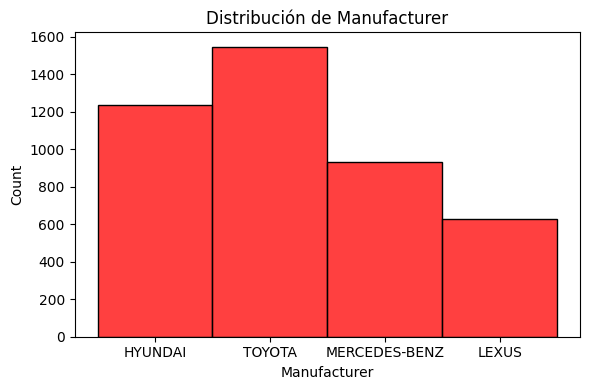

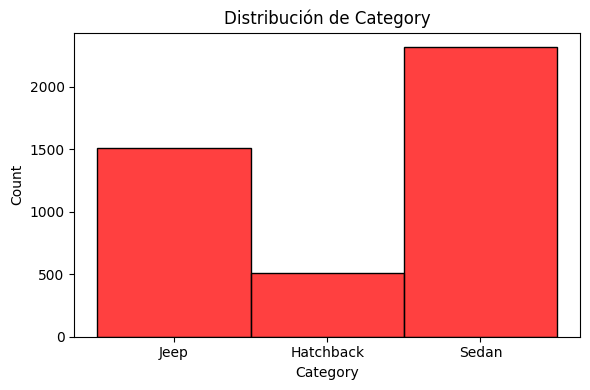

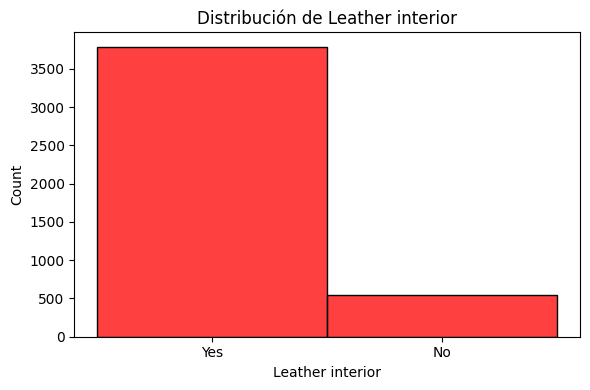

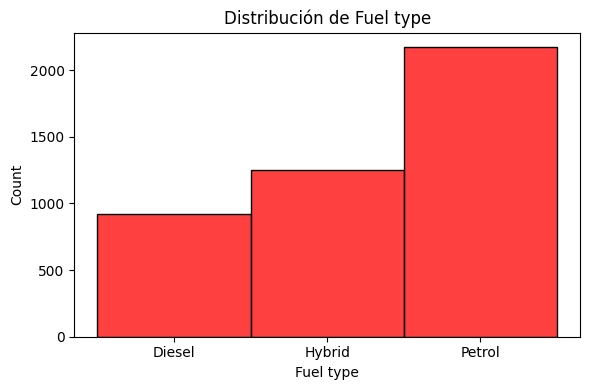

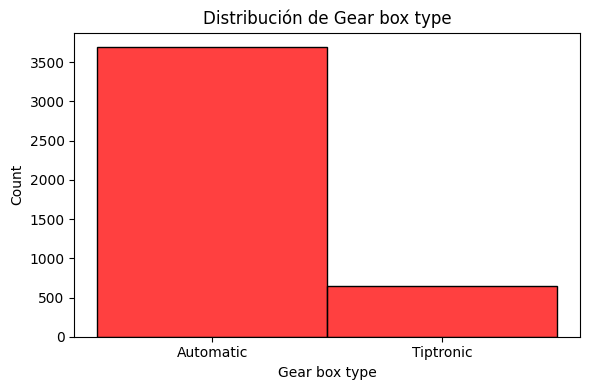

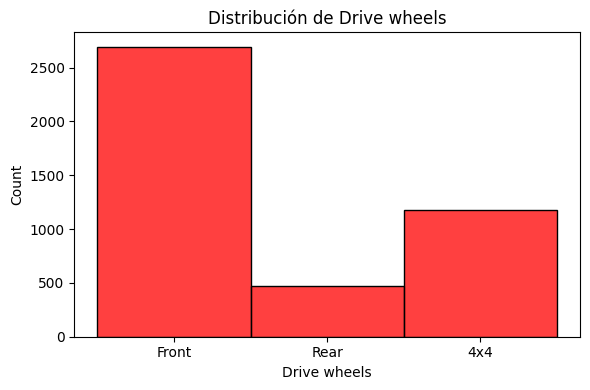

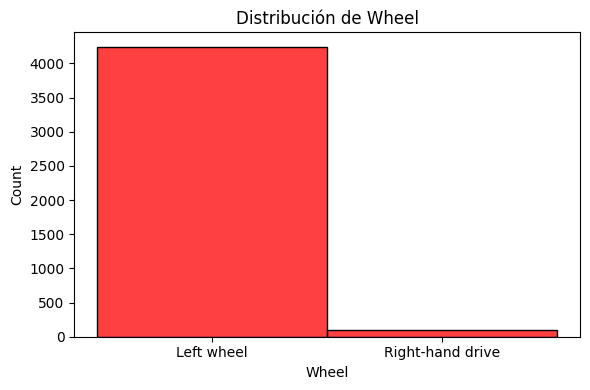

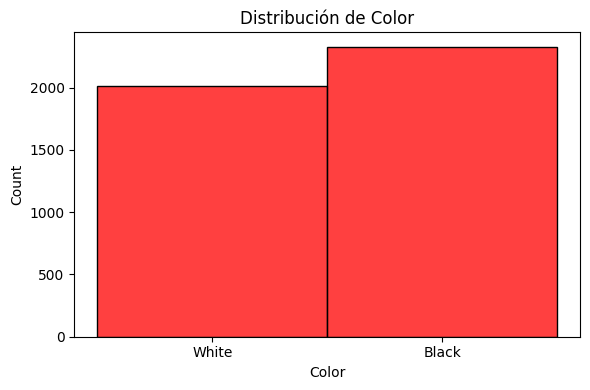

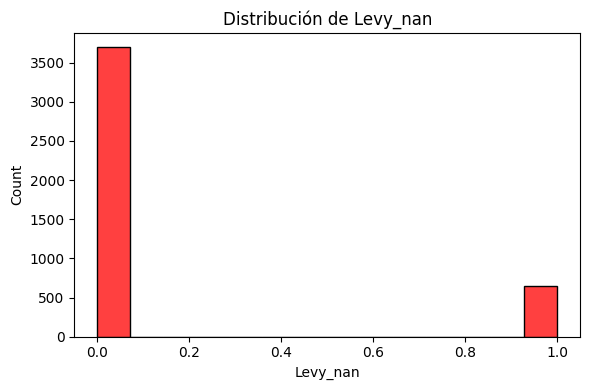

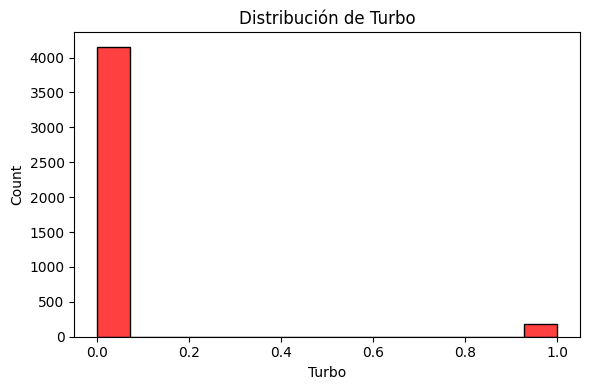

In [87]:
# ESTUDIO DE VARIABLES CATEGÓRICAS

for col in categoricas:
    if col in categoricas:
        plt.figure(figsize=(6, 4))
        sns.histplot(x=df[col], color='r')
        plt.title(f'Distribución de {col}')
        plt.xlabel(col)
        plt.tight_layout()
        plt.show()

In [88]:
# Estadísticos básicos: categóricas 

categoricas.describe()  # Algunas variables parecen desbalanceadas

,Manufacturer,Category,Leather interior,Fuel type,Gear box type,Drive wheels,Wheel,Color,Levy_nan,Turbo
count,4340,4340,4340,4340,4340,4340,4340,4340,4340,4340
unique,4,3,2,3,2,3,2,2,2,2
top,TOYOTA,Sedan,Yes,Petrol,Automatic,Front,Left wheel,Black,False,False
freq,1547,2317,3789,2172,3691,2692,4243,2327,3696,4153


In [89]:
# ESTUDIO DE LA VARIABLE DEPENDIENTE

print("Valores nulos:", df['Color'].isna().sum(), "\n\n", 
      "Muestras de:", df['Color'].value_counts())

# No parece ser una variable desbalanceada.

Valores nulos: 0 

 Muestras de: Color
Black    2327
White    2013
Name: count, dtype: int64


In [90]:
# Vemos la relación con Color (por ser nuestra variable dependiente)

levy_filtro = df[df['Levy_nan'] == False]
levy_filtronan = df[df['Levy_nan'] == True]

Levy: 
 Color
Black    1946
White    1750
Name: count, dtype: int64 

Levy NaN: 
 Color
Black    381
White    263
Name: count, dtype: int64


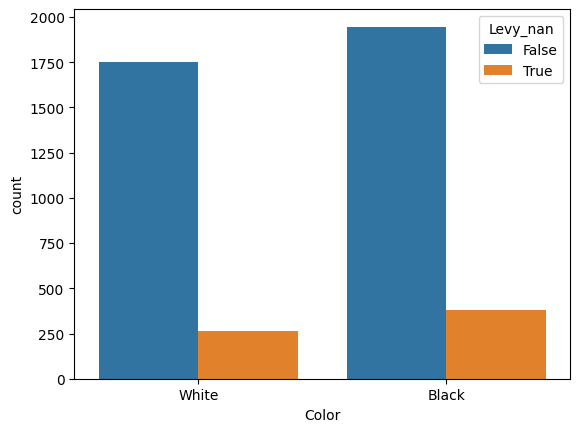

In [91]:
sns.countplot(data=df, x='Color', hue='Levy_nan')

print("Levy:", '\n', levy_filtro["Color"].value_counts(),'\n')

print("Levy NaN:", '\n',
levy_filtronan["Color"].value_counts())

# El hecho de que levy sea NaN o presente un valor parece seguir un patrón similar al que muestra con su propia distribución: no hay relación entre el color y Levy_NaN (como indicaba la V de Cramer).

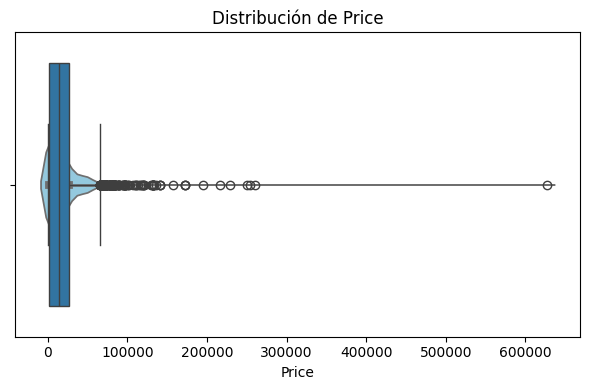

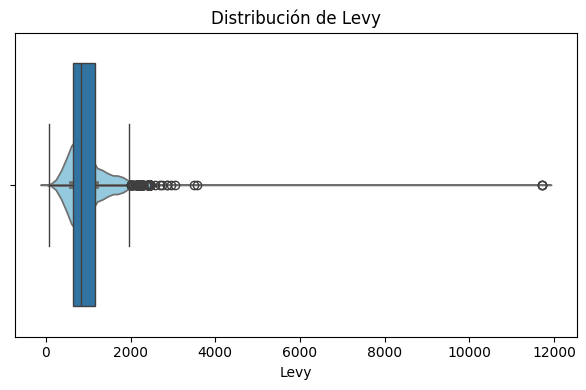

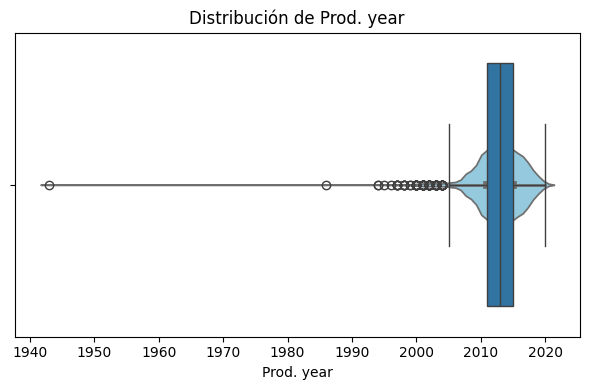

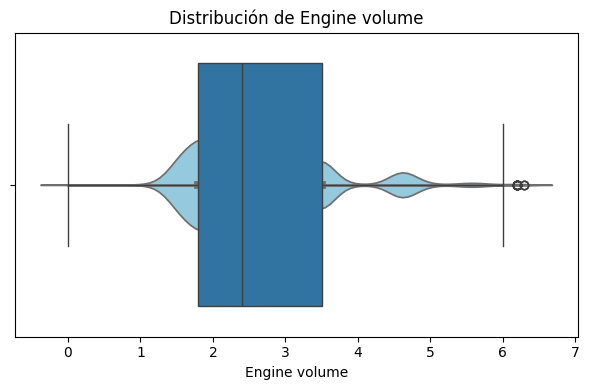

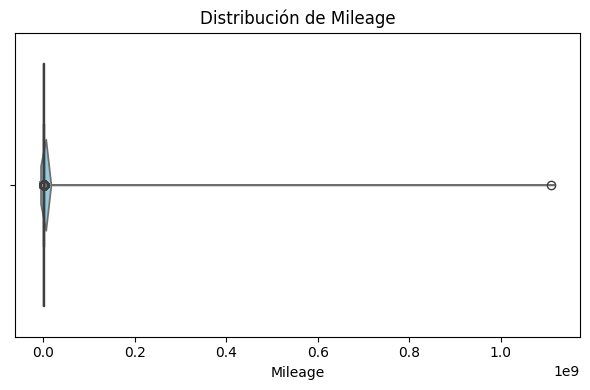

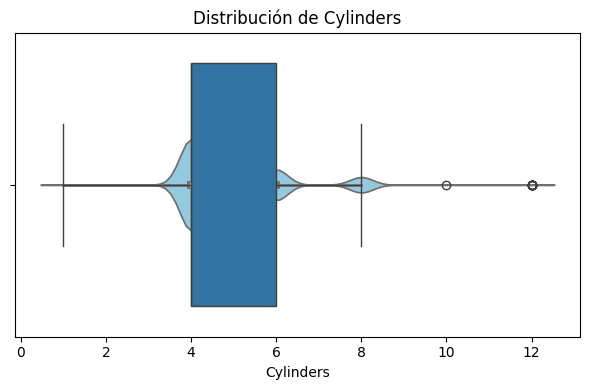

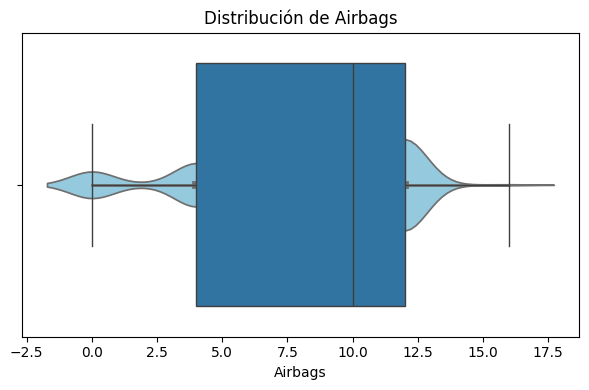

In [92]:
# ESTUDIO DE VARIABLES NUMÉRICAS
# Distribuciones

for col in df.columns:
    if col in numericas:
        plt.figure(figsize=(6, 4))
        sns.violinplot(x=df[col], width=0.3, color='skyblue')
        sns.boxplot(x=df[col])
        plt.title(f'Distribución de {col}')
        plt.xlabel(col)
        plt.tight_layout()
        plt.show()
    

In [93]:
# Estadísticos básicos: numéricas 

numericas.describe()   # Claramente hay datos atípicos

,Price,Levy,Prod. year,Engine volume,Mileage,Cylinders,Airbags
count,4340.000000,3696.000000,4340.00000,4340.000000,4.340000e+03,4340.000000,4340.000000
mean,19161.052765,981.525974,2012.84977,2.614747,3.960525e+05,4.916129,7.884101
std,23990.524855,553.004177,3.59624,1.013176,1.686423e+07,1.429085,4.600287
min,3.000000,87.000000,1943.00000,0.000000,0.000000e+00,1.000000,0.000000
25%,1725.000000,640.000000,2011.00000,1.800000,6.991800e+04,4.000000,4.000000
50%,14113.000000,836.000000,2013.00000,2.400000,1.275150e+05,4.000000,10.000000
75%,27065.000000,1172.000000,2015.00000,3.500000,1.865420e+05,6.000000,12.000000
max,627220.000000,11714.000000,2020.00000,6.300000,1.111111e+09,12.000000,16.000000


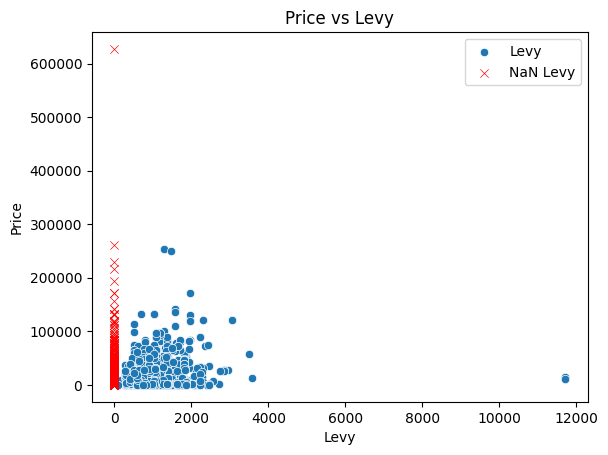

In [94]:
# Vemos la relación con Price (a priori deberían tener algo de relación por ser variables monetarias)

levy_filtro = df[df['Levy'].notna()]
levy_filtrona = df[df['Levy'].isna()]

sns.scatterplot(x=levy_filtro['Levy'], y=levy_filtro['Price'], marker='o', label="Levy")

# Para poder visualizar los NaN
sns.scatterplot(x=[0]*len(levy_filtrona), y=levy_filtrona['Price'], marker='x', color='red', label="NaN Levy")

plt.xlabel("Levy")
plt.ylabel("Price")
plt.title("Price vs Levy")
plt.legend()
plt.show()

In [95]:
# Viendo las distribuciones no parece ni que sean especialmente parecidas ni razonable asumir normalidad, por lo que usaré el índice interquartílico (el mismo que se usa en los plots) en lugar de otros criterios.

from collections import Counter

outliers = {}

for col in df.columns:
    if col in numericas:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1

        li = Q1 - 1.5 * IQR   # Límite inferior
        ls = Q3 + 1.5 * IQR   # Límite superior

        # Máscara booleana para detectar outliers
        mask = (df[col] < li) | (df[col] > ls)

        # Guardamos outliers
        outliers[col] = df.index[mask].tolist()

# Contamos cuanto se repiten los valores entre distintas claves (para detectar caso completamente atípicos)
lista_indices = [ind for indices in outliers.values() for ind in indices]
conteo_indices = Counter(lista_indices)

print("Atípicos más repetidos:", '\n', conteo_indices,'\n')

for col, ind in outliers.items():
    print(f"{col}", "tiene", len(outliers[col]), "atípicos y son:\n",f"{ind}")

Atípicos más repetidos: 
 Counter({1125: 3, 31: 3, 4285: 3, 28: 2, 176: 2, 298: 2, 637: 2, 1514: 2, 1830: 2, 2486: 2, 3044: 2, 3475: 2, 3556: 2, 3736: 2, 329: 2, 486: 2, 503: 2, 1053: 2, 1227: 2, 1372: 2, 1616: 2, 1628: 2, 2253: 2, 2336: 2, 2593: 2, 2608: 2, 2717: 2, 3231: 2, 3325: 2, 3813: 2, 3887: 2, 4279: 2, 147: 2, 676: 2, 1194: 2, 2581: 2, 3760: 2, 722: 2, 43: 1, 56: 1, 100: 1, 101: 1, 140: 1, 158: 1, 180: 1, 213: 1, 256: 1, 268: 1, 284: 1, 292: 1, 297: 1, 315: 1, 334: 1, 343: 1, 362: 1, 378: 1, 413: 1, 460: 1, 514: 1, 543: 1, 586: 1, 617: 1, 631: 1, 668: 1, 690: 1, 702: 1, 707: 1, 801: 1, 834: 1, 911: 1, 919: 1, 952: 1, 1025: 1, 1059: 1, 1067: 1, 1070: 1, 1071: 1, 1077: 1, 1088: 1, 1183: 1, 1202: 1, 1211: 1, 1244: 1, 1294: 1, 1305: 1, 1330: 1, 1344: 1, 1409: 1, 1456: 1, 1475: 1, 1490: 1, 1518: 1, 1545: 1, 1620: 1, 1662: 1, 1678: 1, 1743: 1, 1761: 1, 1765: 1, 1822: 1, 1860: 1, 1929: 1, 1968: 1, 2051: 1, 2085: 1, 2089: 1, 2103: 1, 2132: 1, 2207: 1, 2216: 1, 2219: 1, 2240: 1, 2269: 

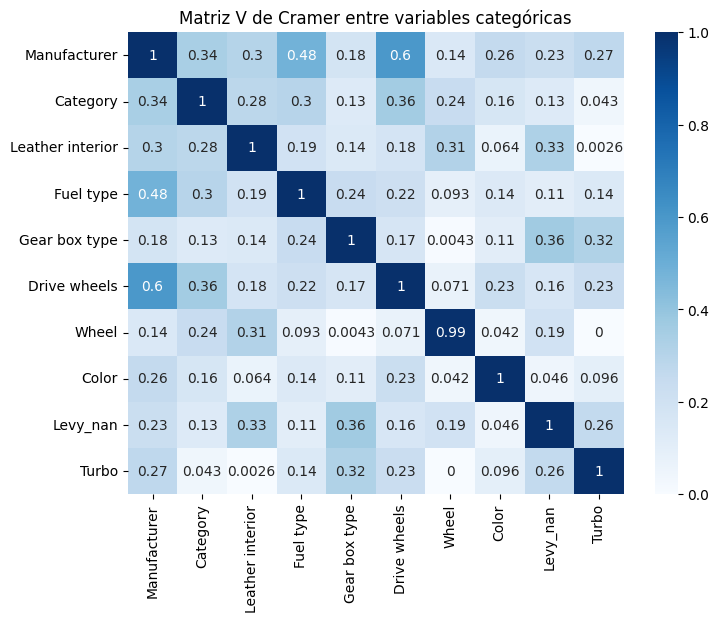

In [ ]:
from scipy.stats import chi2_contingency

def cramers_v(x, y):
    """V de Crammer entre dos variables pandas"""
    confusion_matrix = pd.crosstab(x, y)
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    r, k = confusion_matrix.shape
    return np.sqrt((chi2 / n) / (min(k - 1, r - 1)))

def cramers_v_matrix(df):
    """Matriz de V de Cramer entre todas las columnas del dataframe"""
    cols = df.columns
    n = len(cols)
    result = pd.DataFrame(np.zeros((n, n)), columns=cols, index=cols)
    
    for i, col1 in enumerate(cols):
        for j, col2 in enumerate(cols):
            if i <= j:  
                result.loc[col1, col2] = cramers_v(df[col1], df[col2])
            else:       
                result.loc[col1, col2] = result.loc[col2, col1]
    
    return result

matriz_v = cramers_v_matrix(categoricas)

plt.figure(figsize=(8,6))
sns.heatmap(matriz_v, annot=True, cmap='Blues', vmin=0, vmax=1)
plt.title("Matriz V de Cramer entre variables categóricas")
plt.show()

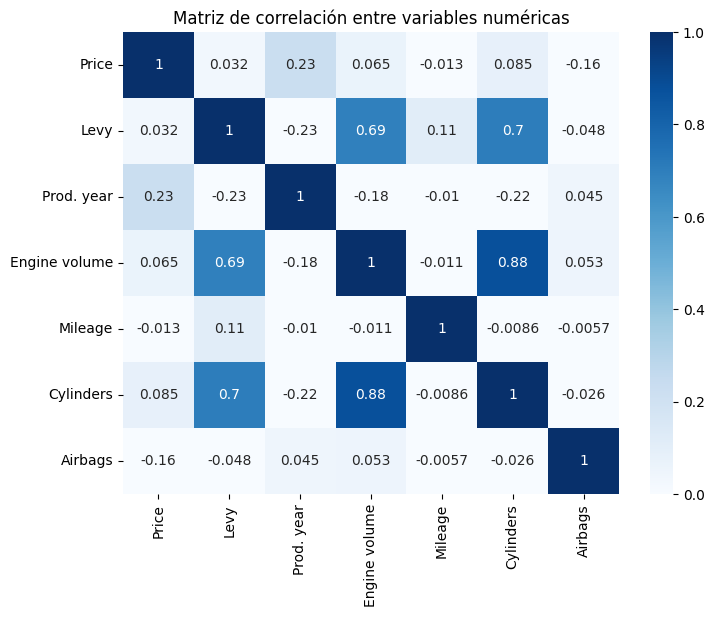

In [ ]:
num_corr= numericas.corr()  # No es tan útil en árboles de decisión *Explicación en pdf

plt.figure(figsize=(8,6))
sns.heatmap(num_corr, annot=True, cmap='Blues', vmin=0, vmax=1)
plt.title("Matriz de correlación entre variables numéricas")
plt.show()

# DEFINICIÓN DE VARIABLES

In [98]:
# Defino variables independientes y dependiente para los modelos:

X = df.drop('Color', axis=1)
y = df['Color']

Xcategoricas= X.select_dtypes(include= ("object","bool"))
Xnumericas= X.drop(Xcategoricas.columns, axis=1)

In [99]:
# Imputamos los NaN de Levy por su mediana (pruebo así porque su distribución es asimétrica).

X['Levy'] = X['Levy'].fillna(X['Levy'].median())

In [100]:
# Hago OneHotEncoding en las categóricas:

X = pd.get_dummies(X, drop_first=True)     # Crea las nuevas variables codificadas

# DEFINICIÓN DEL MODELO

In [101]:
seed= 2000

In [102]:
arbol1 = DecisionTreeClassifier(min_samples_split=30, criterion='gini', max_depth= 4, random_state=seed)

X_train, X_test, y_train, y_test= train_test_split(X, y, test_size=0.2, random_state=seed)

In [103]:
print(f'La frecuencia de cada clase en train es: \n{y_train.value_counts(normalize=True)}')
print(f'\nLa frecuencia de cada clase en test es: \n{y_test.value_counts(normalize=True)}')

La frecuencia de cada clase en train es: 
Color
Black    0.536866
White    0.463134
Name: proportion, dtype: float64

La frecuencia de cada clase en test es: 
Color
Black    0.53341
White    0.46659
Name: proportion, dtype: float64


In [104]:
arbol1.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=4, min_samples_split=30, random_state=2000)

In [105]:
print("Clases:", arbol1.classes_)

print("Variables:", arbol1.feature_names_in_)

tree_rules= export_text(arbol1, feature_names=list(X.columns),show_weights=True)
print(tree_rules)
print("Profundidad del árbol:", arbol1.get_depth())

Clases: ['Black' 'White']
Variables: ['Price' 'Levy' 'Prod. year' 'Engine volume' 'Mileage' 'Cylinders'
 'Airbags' 'Manufacturer_LEXUS' 'Manufacturer_MERCEDES-BENZ'
 'Manufacturer_TOYOTA' 'Category_Jeep' 'Category_Sedan'
 'Leather interior_Yes' 'Fuel type_Hybrid' 'Fuel type_Petrol'
 'Gear box type_Tiptronic' 'Drive wheels_Front' 'Drive wheels_Rear'
 'Wheel_Right-hand drive' 'Levy_nan_True' 'Turbo_True']
|--- Engine volume <= 2.30
|   |--- Manufacturer_MERCEDES-BENZ <= 0.50
|   |   |--- Fuel type_Petrol <= 0.50
|   |   |   |--- Price <= 2116.50
|   |   |   |   |--- weights: [31.00, 142.00] class: White
|   |   |   |--- Price >  2116.50
|   |   |   |   |--- weights: [207.00, 456.00] class: White
|   |   |--- Fuel type_Petrol >  0.50
|   |   |   |--- Price <= 2508.50
|   |   |   |   |--- weights: [50.00, 20.00] class: Black
|   |   |   |--- Price >  2508.50
|   |   |   |   |--- weights: [222.00, 311.00] class: White
|   |--- Manufacturer_MERCEDES-BENZ >  0.50
|   |   |--- Levy <= 901.00
|

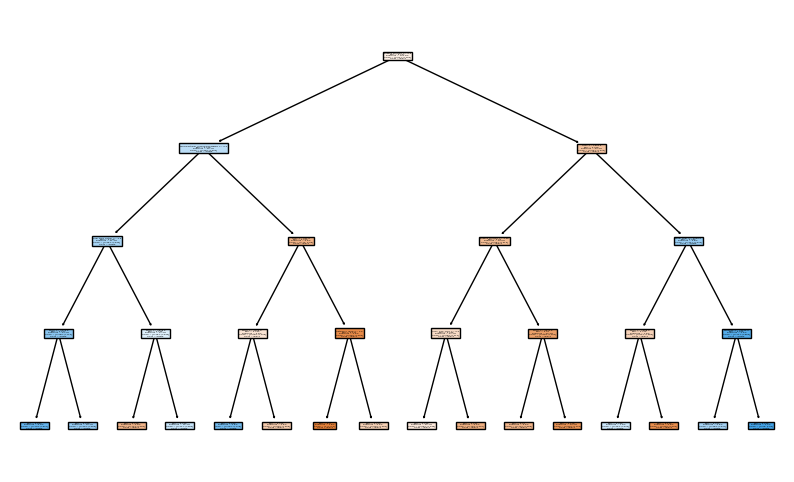

In [106]:
plt.figure(figsize=(10, 6))
plot_tree(arbol1, feature_names=X.columns.tolist(), class_names=arbol1.classes_, filled=True,
proportion= True)
plt.show()

                        nombre  importancia
0                        Price     0.108985
1                         Levy     0.132804
2                   Prod. year     0.045774
3                Engine volume     0.483622
4                      Mileage     0.007178
5                    Cylinders     0.000000
6                      Airbags     0.000000
7           Manufacturer_LEXUS     0.000000
8   Manufacturer_MERCEDES-BENZ     0.127338
9          Manufacturer_TOYOTA     0.000000
10               Category_Jeep     0.009437
11              Category_Sedan     0.000000
12        Leather interior_Yes     0.000000
13            Fuel type_Hybrid     0.000000
14            Fuel type_Petrol     0.057261
15     Gear box type_Tiptronic     0.000000
16          Drive wheels_Front     0.000000
17           Drive wheels_Rear     0.000000
18      Wheel_Right-hand drive     0.000000
19               Levy_nan_True     0.027601
20                  Turbo_True     0.000000


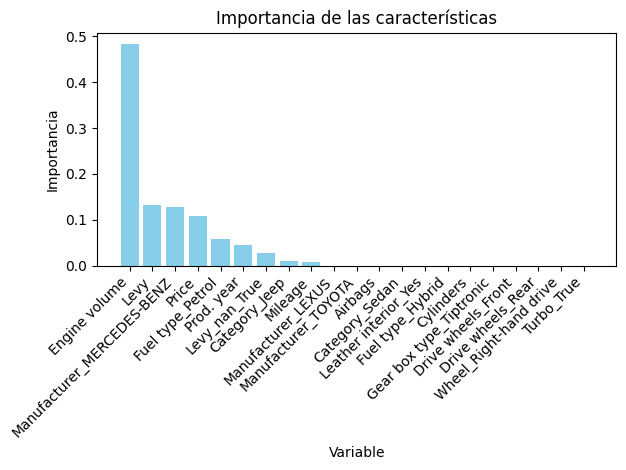

In [107]:
print(pd.DataFrame({'nombre': arbol1.feature_names_in_, 'importancia': arbol1.feature_importances_}))
df_importancia1= pd.DataFrame({'Variable': arbol1.feature_names_in_, 'Importancia': arbol1.feature_importances_}).sort_values(by='Importancia', ascending=False)

plt.bar(df_importancia1['Variable'], df_importancia1['Importancia'], color='skyblue')
plt.xlabel('Variable')
plt.ylabel('Importancia')
plt.title('Importancia de las características')
plt.xticks(rotation=45, ha='right') 
plt.tight_layout()
plt.show()

In [108]:
# Primer intento de optimización
params= {
'max_depth': [2, 3, 5, 10, 20, 30],
'min_samples_split': [5, 10, 20, 50, 100],
'criterion': ["gini", "entropy"]
}

scoring_metrics= ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']

grid_search= GridSearchCV(estimator=arbol1,
             param_grid=params,
             cv=5, scoring= scoring_metrics, refit='accuracy')

grid_search.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=DecisionTreeClassifier(max_depth=4, min_samples_split=30,
                                              random_state=2000),
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [2, 3, 5, 10, 20, 30],
                         'min_samples_split': [5, 10, 20, 50, 100]},
             refit='accuracy',
             scoring=['accuracy', 'precision_macro', 'recall_macro',
                      'f1_macro'])

In [109]:
results= pd.DataFrame(grid_search.cv_results_)

print("Resultados de GridSearch:")
display(results[['params', 'mean_test_accuracy',
'mean_test_precision_macro',
'mean_test_recall_macro', 'mean_test_f1_macro']][:10])

Resultados de GridSearch:


,params,mean_test_accuracy,mean_test_precision_macro,mean_test_recall_macro,mean_test_f1_macro
0,"{'criterion': 'gini', 'max_depth': 2, 'min_sam...",0.667336,0.665446,0.664008,0.664308
1,"{'criterion': 'gini', 'max_depth': 2, 'min_sam...",0.667336,0.665446,0.664008,0.664308
2,"{'criterion': 'gini', 'max_depth': 2, 'min_sam...",0.667336,0.665446,0.664008,0.664308
3,"{'criterion': 'gini', 'max_depth': 2, 'min_sam...",0.667336,0.665446,0.664008,0.664308
4,"{'criterion': 'gini', 'max_depth': 2, 'min_sam...",0.667336,0.665446,0.664008,0.664308
5,"{'criterion': 'gini', 'max_depth': 3, 'min_sam...",0.666756,0.667773,0.664821,0.663447
6,"{'criterion': 'gini', 'max_depth': 3, 'min_sam...",0.666756,0.667773,0.664821,0.663447
7,"{'criterion': 'gini', 'max_depth': 3, 'min_sam...",0.666756,0.667773,0.664821,0.663447
8,"{'criterion': 'gini', 'max_depth': 3, 'min_sam...",0.666756,0.667773,0.664821,0.663447
9,"{'criterion': 'gini', 'max_depth': 3, 'min_sam...",0.666756,0.667773,0.664821,0.663447


In [110]:
# El mejor modelo es:

best_model= grid_search.best_estimator_
print(grid_search.best_estimator_)

DecisionTreeClassifier(criterion='entropy', max_depth=20, min_samples_split=5,
                       random_state=2000)


In [111]:
summary = results[['params', 'mean_test_accuracy', 'mean_test_precision_macro', 'mean_test_recall_macro','mean_test_f1_macro']]

# Resumen de los mejores modelos según la métrica seleccionada.
summary_sorted = summary.sort_values('mean_test_accuracy', ascending=False)

# Mostrar los 7 mejores modelos
top7 = pd.DataFrame(summary_sorted.head(7))
top7

,params,mean_test_accuracy,mean_test_precision_macro,mean_test_recall_macro,mean_test_f1_macro
50,"{'criterion': 'entropy', 'max_depth': 20, 'min...",0.745109,0.744991,0.743363,0.743273
55,"{'criterion': 'entropy', 'max_depth': 30, 'min...",0.743955,0.742901,0.742138,0.742269
56,"{'criterion': 'entropy', 'max_depth': 30, 'min...",0.742516,0.741445,0.740000,0.740406
20,"{'criterion': 'gini', 'max_depth': 20, 'min_sa...",0.741653,0.740490,0.740297,0.740206
51,"{'criterion': 'entropy', 'max_depth': 20, 'min...",0.740496,0.739535,0.738143,0.738467
46,"{'criterion': 'entropy', 'max_depth': 10, 'min...",0.739923,0.739280,0.739873,0.739060
45,"{'criterion': 'entropy', 'max_depth': 10, 'min...",0.739922,0.739634,0.740300,0.739171


In [128]:
def boxplot_accuracy(cv_results, top_n=5):
    
    results = pd.DataFrame(cv_results)

    # Ordenar por mean_test_accuracy
    top_models = results.sort_values('mean_test_accuracy', ascending=False).head(top_n)

    # Preparar los datos de los splits
    split_cols = [col for col in results.columns if 'split' in col and 'accuracy' in col]
    res_list = []

    for idx in top_models.index:
        splits = top_models.loc[idx, split_cols].values
        res_list.append(splits)

    # Crear labels con los índices de los modelos
    labels = [f'Model_{i+1}' for i in range(top_n)]

    # Dibujar boxplot
    plt.figure(figsize=(8,5))
    plt.boxplot(res_list, labels=labels)
    plt.title(f'Boxplots de Accuracy para los {len(split_cols)} splits de las {top_n} mejores parametrizaciones')
    plt.xlabel('Modelos')
    plt.ylabel('Accuracy')
    plt.show()     

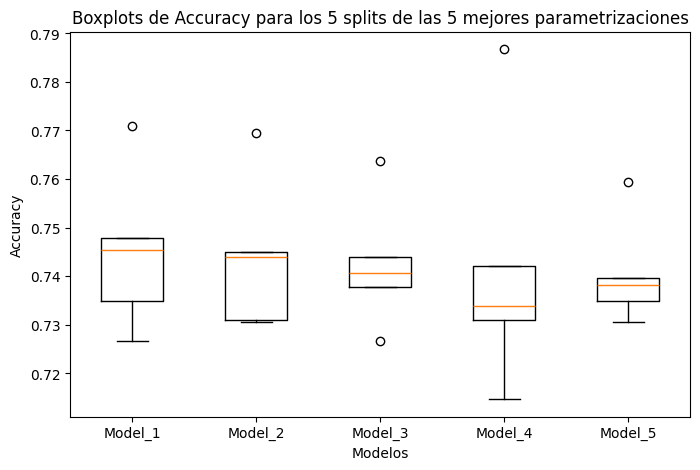

In [129]:
boxplot_accuracy(results, 5)

In [157]:
    # Predicciones
    y_test_pred = grid_search.best_estimator_.predict(X_test)
    y_train_pred= grid_search.best_estimator_.predict(X_train)

In [162]:
    # Matrices de confusión
    mat_conf_train = confusion_matrix(y_train, y_train_pred)
    print("\nMatriz de confusión de train:\n",mat_conf_train,"\n")

    mat_conf_test = confusion_matrix(y_test, y_test_pred)
    print("Matriz de confusión de test:\n",mat_conf_test,"\n")

    # Informe sobre las predicciones
    cr_train= classification_report(y_train, y_train_pred)
    cr_test= classification_report(y_test, y_test_pred)

    print("\nInforme de clasificación: train\n",cr_train)
    print("\nInforme de clasificación: test\n",cr_test)


Matriz de confusión de train:
 [[1738  126]
 [  85 1523]] 

Matriz de confusión de test:
 [[352 111]
 [116 289]] 


Informe de clasificación: train
               precision    recall  f1-score   support

       Black       0.95      0.93      0.94      1864
       White       0.92      0.95      0.94      1608

    accuracy                           0.94      3472
   macro avg       0.94      0.94      0.94      3472
weighted avg       0.94      0.94      0.94      3472


Informe de clasificación: test
               precision    recall  f1-score   support

       Black       0.75      0.76      0.76       463
       White       0.72      0.71      0.72       405

    accuracy                           0.74       868
   macro avg       0.74      0.74      0.74       868
weighted avg       0.74      0.74      0.74       868




Áreabajo la curva ROC (AUC): 0.99


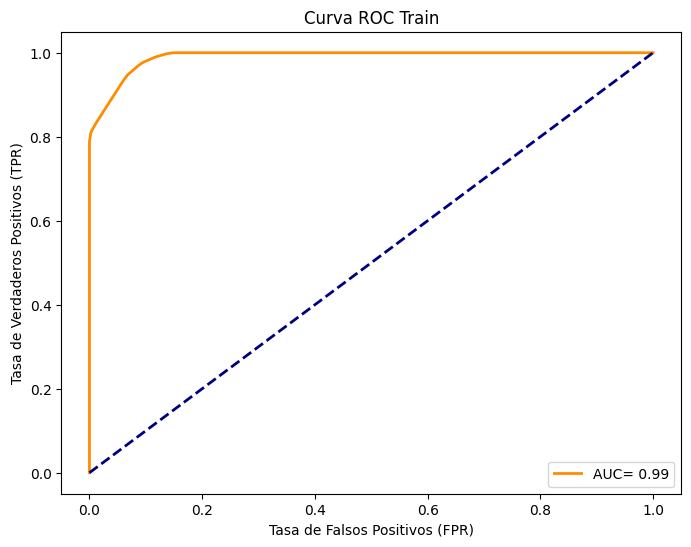

In [ ]:
y_train_auc= pd.get_dummies(y_train,drop_first=True)
# Calcular el área bajo la curva ROC (AUC)
y_prob_train= best_model.predict_proba(X_train)[:, 1]
fpr, tpr, thresholds= roc_curve(y_train_auc, y_prob_train)
roc_auc= auc(fpr, tpr)
print(f"\nÁreabajo la curva ROC (AUC) Train: {roc_auc:.2f}")
# Graficar la curva ROC
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'AUC= {roc_auc:.2f}')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('Tasa de Falsos Positivos (FPR)')
plt.ylabel('Tasa de Verdaderos Positivos (TPR)')
plt.title('Curva ROC Train')
plt.legend(loc="lower right")
plt.show()


Áreabajo la curva ROC (AUC): 0.99


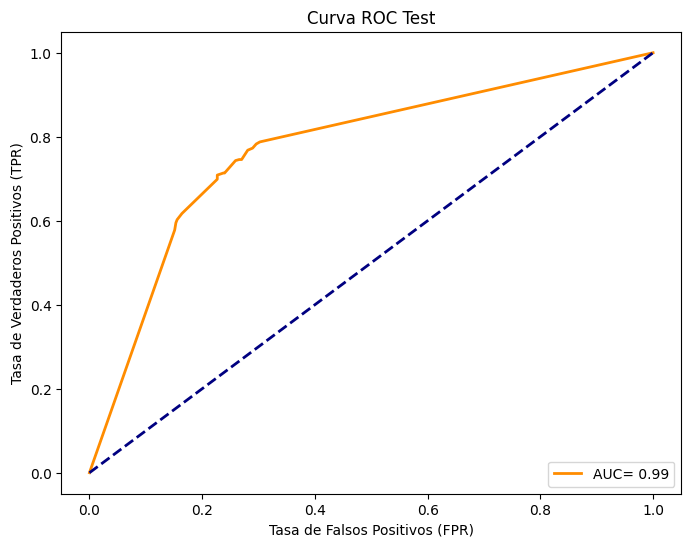

In [ ]:
y_test_auc= pd.get_dummies(y_test,drop_first=True)
# Calcular el área bajo la curva ROC (AUC)
y_prob_test= best_model.predict_proba(X_test)[:, 1]
fpr, tpr, thresholds= roc_curve(y_test_auc, y_prob_test)
roc_auc_test= auc(fpr, tpr)
print(f"\nÁreabajo la curva ROC (AUC) Test: {roc_auc:.2f}")
# Graficar la curva ROC
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'AUC= {roc_auc:.2f}')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('Tasa de Falsos Positivos (FPR)')
plt.ylabel('Tasa de Verdaderos Positivos (TPR)')
plt.title('Curva ROC Test')
plt.legend(loc="lower right")
plt.show()

# GENERALIZO LA EJECUCIÓN DEL MODELO

In [ ]:
def modelo_gridsearch(X, y, model, params, refit,cv=5, scoring=scoring_metrics, metrics=scoring_metrics, test_size=0.2, random_state=0, top_n=7):
    
    scoring_metrics = ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']
    
    # Train/Test split
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=random_state)
    
    cv=cv

    refit= 'accuracy'
    # GridSearch con CV
    grid_search = GridSearchCV(
        estimator=model,
        param_grid=params,
        cv=cv,
        scoring=scoring_metrics,
        refit=refit,          
        n_jobs=-1
    )
    
    grid_search.fit(X_train, y_train)
    
    best_model= grid_search.best_estimator_
    
    # Predicciones
    y_test_pred = grid_search.best_estimator_.predict(X_test)
    y_train_pred= grid_search.best_estimator_.predict(X_train)

    # Mejor modelo
    results = pd.DataFrame(grid_search.cv_results_)
    summary = results[['params', 'mean_test_accuracy', 'mean_test_precision_macro', 'mean_test_recall_macro','mean_test_f1_macro']]
    summary_sorted = summary.sort_values('mean_test_accuracy', ascending=False)
    
    print("Mejor modelo encontrado:\n", grid_search.best_index_, ":",grid_search.best_estimator_)
    print("\nAccuracy del mejor modelo:\n", summary_sorted.head(top_n)['mean_test_accuracy'].iloc[0])
    
    # Matrices de confusión
    mat_conf_train = confusion_matrix(y_train, y_train_pred)
    print("\nMatriz de confusión de train:\n",mat_conf_train,"\n")

    mat_conf_test = confusion_matrix(y_test, y_test_pred)
    print("Matriz de confusión de test:\n",mat_conf_test,"\n")

    # Informe sobre las predicciones
    cr_train= classification_report(y_train, y_train_pred)
    cr_test= classification_report(y_test, y_test_pred)

    # Resultados resumidos

    print("\nInforme de clasificación: train\n",cr_train)
    print("\nInforme de clasificación: test\n",cr_test)
    print(f"\nMétricas de los primeros {top_n} modelos ordenados por {refit}:")
    display(summary_sorted.head(top_n))

    # Importancia de las variables

    df_importancia= pd.DataFrame({'Variable': grid_search.best_estimator_.feature_names_in_, 'Importancia': grid_search.best_estimator_.feature_importances_}).sort_values(by='Importancia', ascending=False)

    plt.bar(df_importancia['Variable'], df_importancia['Importancia'], color='skyblue')
    plt.xlabel('Variable')
    plt.ylabel('Importancia')
    plt.title('Importancia de las características')
    plt.xticks(rotation=45, ha='right') 
    plt.tight_layout()
    plt.show()

    #Curvas ROC
    #Train
    y_train_auc= pd.get_dummies(y_train,drop_first=True)
    y_prob_train= best_model.predict_proba(X_train)[:, 1]
    fpr, tpr, thresholds= roc_curve(y_train_auc, y_prob_train)
    roc_auc= auc(fpr, tpr)
    print(f"\nÁreabajo la curva ROC (AUC) Train: {roc_auc:.2f}")
    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'AUC= {roc_auc:.2f}')
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlabel('Tasa de Falsos Positivos (FPR)')
    plt.ylabel('Tasa de Verdaderos Positivos (TPR)')
    plt.title('Curva ROC Train')
    plt.legend(loc="lower right")
    plt.show()

    #Test
    y_test_auc= pd.get_dummies(y_test,drop_first=True)
    y_prob_test= best_model.predict_proba(X_test)[:, 1]
    fpr, tpr, thresholds= roc_curve(y_test_auc, y_prob_test)
    roc_auc_test= auc(fpr, tpr)
    print(f"\nÁreabajo la curva ROC (AUC) Test: {roc_auc:.2f}")
    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'AUC= {roc_auc:.2f}')
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlabel('Tasa de Falsos Positivos (FPR)')
    plt.ylabel('Tasa de Verdaderos Positivos (TPR)')
    plt.title('Curva ROC Test')
    plt.legend(loc="lower right")
    plt.show()
    
    # Boxplots de las parametrizaciones
    boxplot_accuracy(grid_search.cv_results_, cv)
    return summary_sorted.head(top_n), grid_search.best_estimator_, grid_search.best_index_, df_importancia

## X2: Eliminación de outliers extremos

In [170]:
# Definimos outliers más extremos

outliers = {}

for col in df.columns:
    if col in numericas:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1

        li = Q1 - 3 * IQR   # Límite inferior
        ls = Q3 + 3 * IQR   # Límite superior

        # Máscara booleana para detectar outliers
        mask = (df[col] < li) | (df[col] > ls)

        # Guardamos outliers
        outliers[col] = df.index[mask].tolist()

# Contamos cuanto se repiten los valores entre distintas claves (para detectar caso completamente atípicos)
lista_indices = [ind for indices in outliers.values() for ind in indices]
conteo_indices = Counter(lista_indices)

print("Atípicos más repetidos:", '\n', conteo_indices,'\n')

for col, ind in outliers.items():
    print(f"{col}", "tiene", len(outliers[col]), "atípicos y son:\n",f"{ind}")

Atípicos más repetidos: 
 Counter({1125: 2, 1514: 2, 180: 1, 256: 1, 284: 1, 292: 1, 298: 1, 343: 1, 637: 1, 668: 1, 690: 1, 707: 1, 919: 1, 1330: 1, 1490: 1, 1545: 1, 1662: 1, 1678: 1, 2085: 1, 2103: 1, 2337: 1, 2441: 1, 2995: 1, 3133: 1, 3230: 1, 3241: 1, 3297: 1, 3359: 1, 3475: 1, 3477: 1, 3516: 1, 3801: 1, 3985: 1, 4055: 1, 4113: 1, 4195: 1, 31: 1, 303: 1, 316: 1, 1332: 1, 1458: 1, 4175: 1, 4279: 1, 4285: 1, 121: 1, 147: 1, 210: 1, 296: 1, 437: 1, 676: 1, 714: 1, 1000: 1, 1050: 1, 1066: 1, 1143: 1, 1346: 1, 2941: 1, 3591: 1, 3760: 1, 125: 1, 212: 1, 280: 1, 387: 1, 722: 1, 1194: 1, 1333: 1, 2177: 1, 2783: 1, 2845: 1, 3219: 1, 3385: 1, 3407: 1, 3597: 1, 3779: 1}) 

Price tiene 36 atípicos y son:
 [180, 256, 284, 292, 298, 343, 637, 668, 690, 707, 919, 1125, 1330, 1490, 1514, 1545, 1662, 1678, 2085, 2103, 2337, 2441, 2995, 3133, 3230, 3241, 3297, 3359, 3475, 3477, 3516, 3801, 3985, 4055, 4113, 4195]
Levy tiene 9 atípicos y son:
 [31, 303, 316, 1125, 1332, 1458, 4175, 4279, 4285]
Prod

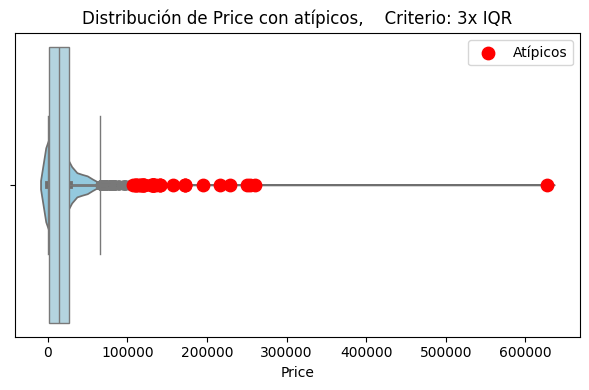

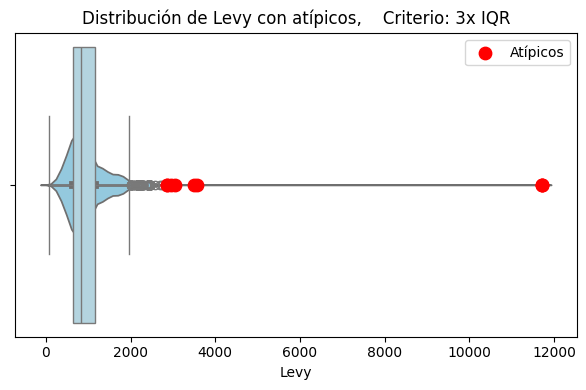

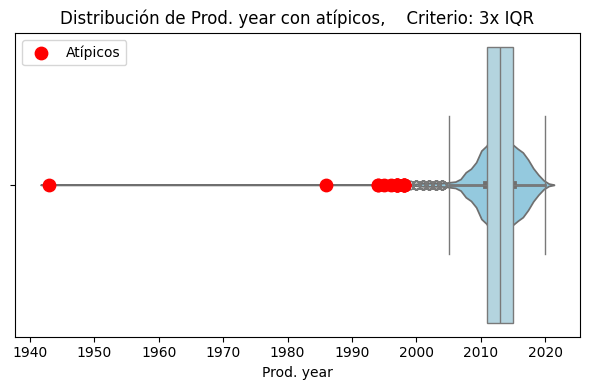

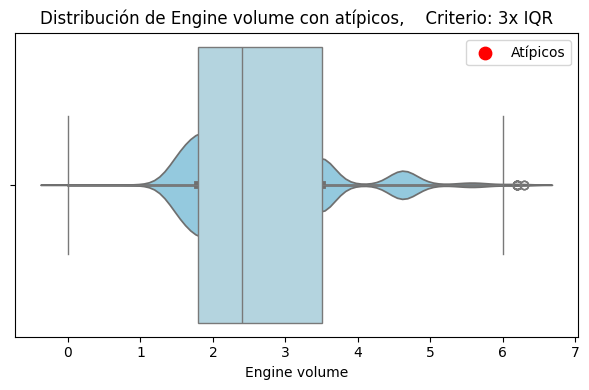

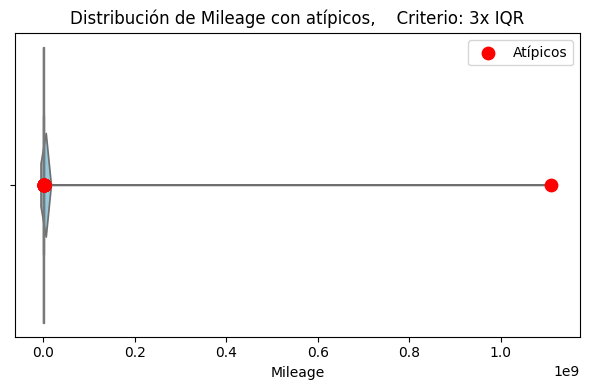

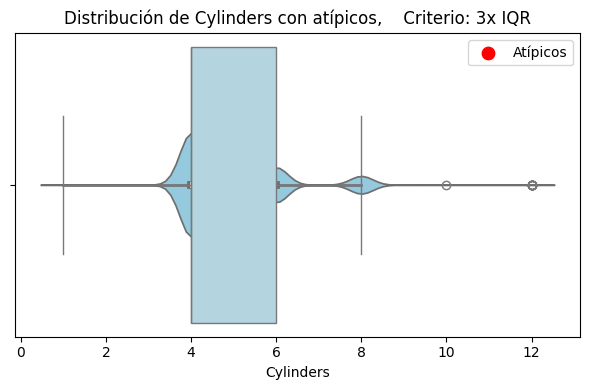

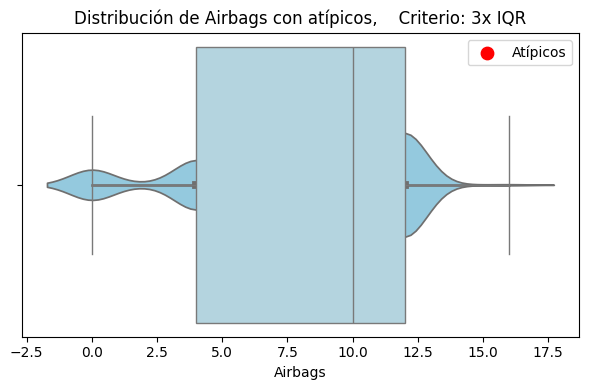

In [ ]:
# Valores más extremos

for col in numericas: 
    plt.figure(figsize=(6, 4))
    
    # violin + Boxplot
    sns.violinplot(x=df[col], width=0.3, color='skyblue')
    sns.boxplot(x=df[col], color="lightblue")

    # outliers en rojo
    plt.scatter(
        df.loc[outliers[col], col],     
        np.full(len(outliers[col]), 0),  
        color="red", s=80, marker="o", zorder=3,
        label="Atípicos"
    )

    plt.title(f"Distribución de {col} con atípicos,    Criterio: 3x IQR")
    plt.legend()
    plt.xlabel(col)
    plt.tight_layout()
    plt.show()

In [ ]:
# Reemplazo valores atípicos por mediana porque valores muy extremos pueden dar ramificaciones poco útiles. 

df_copy = X.copy()
    
for col in numericas:
    Q1 = df_copy[col].quantile(0.25)
    Q3 = df_copy[col].quantile(0.75)
    IQR = Q3 - Q1
    li = Q1 - 3 * IQR   # límite inferior
    ls = Q3 + 3 * IQR   # límite superior
    mask = (df_copy[col] < li) | (df_copy[col] > ls)
    mediana = df_copy[col].median()
    df_copy.loc[mask, col] = mediana

X2= df_copy

print("Muestras con atípicos reemplazadas:", len(list(conteo_indices.keys())))
print(X.shape)
print(X2.shape)
print(y.shape)

Muestras con atípicos reemplazadas: 74
(4340, 21)
(4340, 21)
(4340,)


Mejor modelo encontrado:
 20 : DecisionTreeClassifier(max_depth=20, min_samples_split=5, random_state=2000)

Accuracy del mejor modelo:
 0.7523052681773889

Matriz de confusión de train:
 [[1781   67]
 [  82 1542]] 

Matriz de confusión de test:
 [[380  99]
 [103 286]] 


Informe de clasificación: train
               precision    recall  f1-score   support

       Black       0.96      0.96      0.96      1848
       White       0.96      0.95      0.95      1624

    accuracy                           0.96      3472
   macro avg       0.96      0.96      0.96      3472
weighted avg       0.96      0.96      0.96      3472


Informe de clasificación: test
               precision    recall  f1-score   support

       Black       0.79      0.79      0.79       479
       White       0.74      0.74      0.74       389

    accuracy                           0.77       868
   macro avg       0.76      0.76      0.76       868
weighted avg       0.77      0.77      0.77       868


Métric

,params,mean_test_accuracy,mean_test_precision_macro,mean_test_recall_macro,mean_test_f1_macro
20,"{'criterion': 'gini', 'max_depth': 20, 'min_sa...",0.752305,0.751655,0.751211,0.751138
25,"{'criterion': 'gini', 'max_depth': 30, 'min_sa...",0.748560,0.747888,0.746983,0.747131
21,"{'criterion': 'gini', 'max_depth': 20, 'min_sa...",0.747695,0.747186,0.746469,0.746397
50,"{'criterion': 'entropy', 'max_depth': 20, 'min...",0.747407,0.746884,0.746677,0.746368
55,"{'criterion': 'entropy', 'max_depth': 30, 'min...",0.744531,0.743656,0.742931,0.743127
26,"{'criterion': 'gini', 'max_depth': 30, 'min_sa...",0.743661,0.743063,0.741896,0.742076
15,"{'criterion': 'gini', 'max_depth': 10, 'min_sa...",0.743090,0.743335,0.743147,0.742233


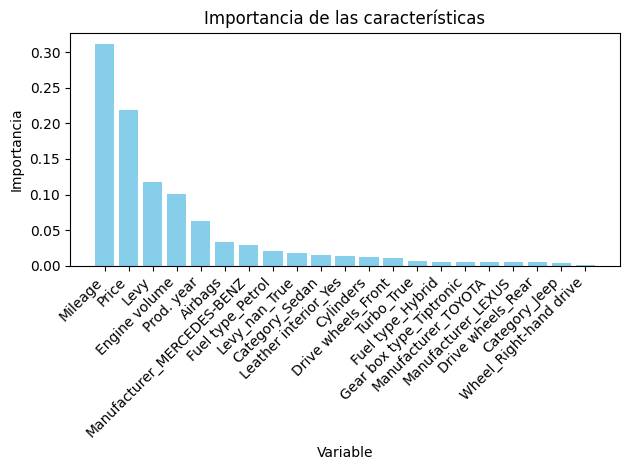


Áreabajo la curva ROC (AUC) Train: 1.00


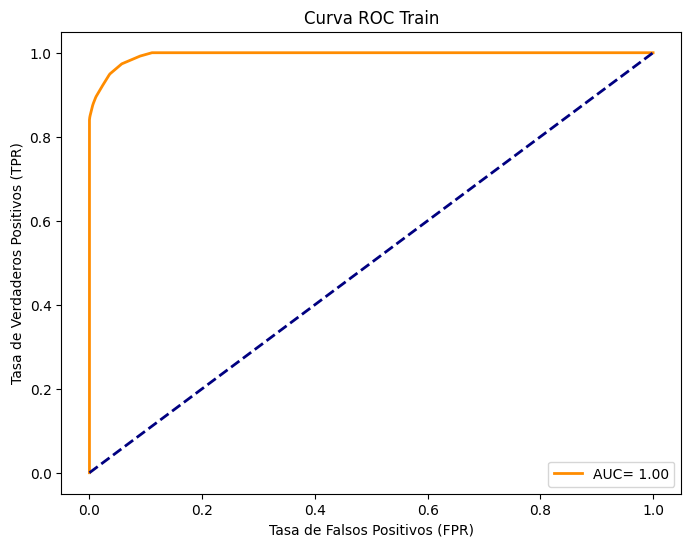


Áreabajo la curva ROC (AUC) Test: 1.00


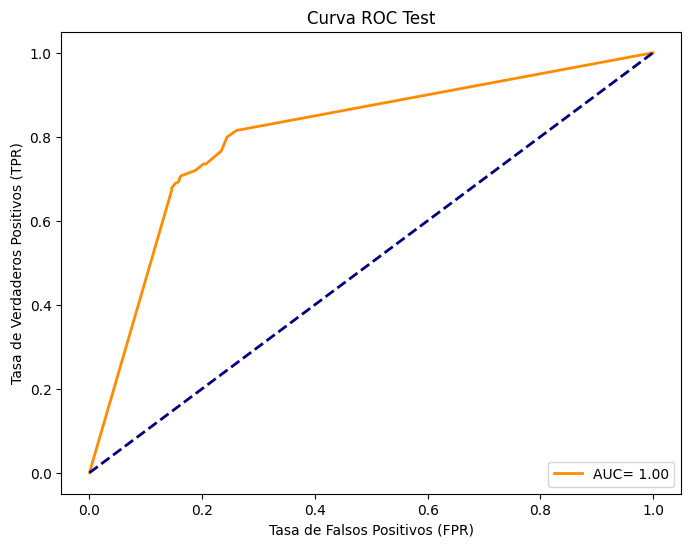

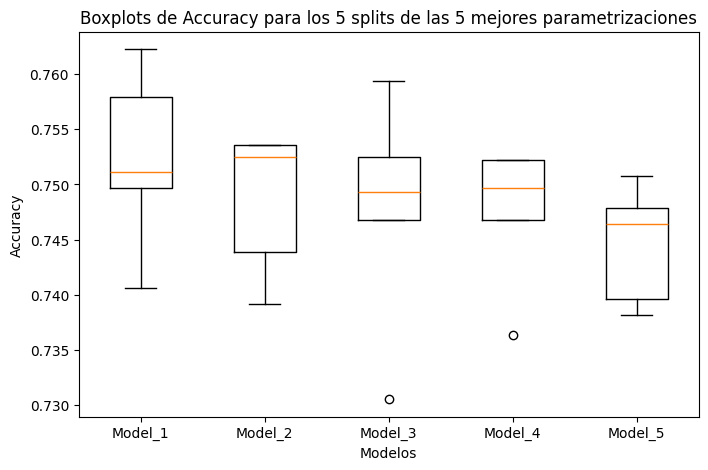

In [ ]:
arbol1 = DecisionTreeClassifier(random_state=seed)


params= {
'max_depth': [2, 3, 5, 10, 20, 30],
'min_samples_split': [5, 10, 20, 50, 100],
'criterion': ["gini", "entropy"]
}


top7_2, best_model_2, indice2, df_importancia2 = modelo_gridsearch(X2, y, arbol1, params, refit='accuracy', scoring=scoring_metrics, top_n=7)

## X3: Normalización de variables numéricas

In [ ]:
# Normalización de numéricas (no es necesaria, tanto árboles como xgboost funcionan mediante umbrales no por distancias; simplemente es una prueba)

X2categoricas= X2.select_dtypes(include= ("object","bool"))
X2numericas= X2.drop(X2categoricas.columns, axis=1)


X2_norm = StandardScaler().fit_transform(X2numericas)

X2_norm = pd.DataFrame(X2_norm, columns=X2numericas.columns, index=X2.index)

X3 = pd.concat([X2_norm, X2categoricas], axis=1)

X3.head()

,Price,Levy,Prod. year,Engine volume,Mileage,Cylinders,Airbags,Manufacturer_LEXUS,Manufacturer_MERCEDES-BENZ,Manufacturer_TOYOTA,...,Category_Sedan,Leather interior_Yes,Fuel type_Hybrid,Fuel type_Petrol,Gear box type_Tiptronic,Drive wheels_Front,Drive wheels_Rear,Wheel_Right-hand drive,Levy_nan_True,Turbo_True
0,1.172089,-0.051675,0.936314,-0.606822,0.263092,-0.641134,-0.844414,False,False,False,...,False,True,False,False,False,True,False,False,False,False
1,-0.876949,-0.421953,-0.890435,-0.804244,1.346211,-0.641134,0.894808,False,False,True,...,False,True,True,False,False,True,False,False,False,False
2,-0.915277,-1.467275,0.327398,-0.113267,2.884585,-0.641134,0.894808,False,False,True,...,True,True,True,False,False,True,False,False,False,False
3,-0.923812,0.409748,0.327398,0.873842,0.523276,0.758524,0.894808,False,True,False,...,True,True,False,False,False,False,True,False,False,False
4,-0.919572,0.415445,0.022940,0.873842,0.010017,0.758524,0.894808,True,False,False,...,False,True,True,False,False,True,False,False,False,False


Mejor modelo encontrado:
 20 : DecisionTreeClassifier(max_depth=20, min_samples_split=5, random_state=2000)

Accuracy del mejor modelo:
 0.7531694068376423

Matriz de confusión de train:
 [[1781   67]
 [  82 1542]] 

Matriz de confusión de test:
 [[380  99]
 [103 286]] 


Informe de clasificación: train
               precision    recall  f1-score   support

       Black       0.96      0.96      0.96      1848
       White       0.96      0.95      0.95      1624

    accuracy                           0.96      3472
   macro avg       0.96      0.96      0.96      3472
weighted avg       0.96      0.96      0.96      3472


Informe de clasificación: test
               precision    recall  f1-score   support

       Black       0.79      0.79      0.79       479
       White       0.74      0.74      0.74       389

    accuracy                           0.77       868
   macro avg       0.76      0.76      0.76       868
weighted avg       0.77      0.77      0.77       868


Métric

,params,mean_test_accuracy,mean_test_precision_macro,mean_test_recall_macro,mean_test_f1_macro
20,"{'criterion': 'gini', 'max_depth': 20, 'min_sa...",0.753169,0.752514,0.752097,0.752021
25,"{'criterion': 'gini', 'max_depth': 30, 'min_sa...",0.748272,0.747572,0.746749,0.746882
21,"{'criterion': 'gini', 'max_depth': 20, 'min_sa...",0.747695,0.747158,0.746469,0.746408
50,"{'criterion': 'entropy', 'max_depth': 20, 'min...",0.747408,0.746827,0.746640,0.746361
15,"{'criterion': 'gini', 'max_depth': 10, 'min_sa...",0.743666,0.743922,0.743763,0.742830
55,"{'criterion': 'entropy', 'max_depth': 30, 'min...",0.743379,0.742484,0.741774,0.741970
26,"{'criterion': 'gini', 'max_depth': 30, 'min_sa...",0.743374,0.742811,0.741590,0.741764


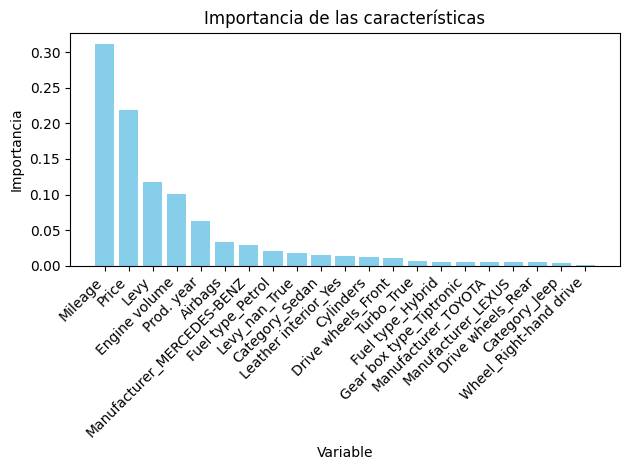


Áreabajo la curva ROC (AUC) Train: 1.00


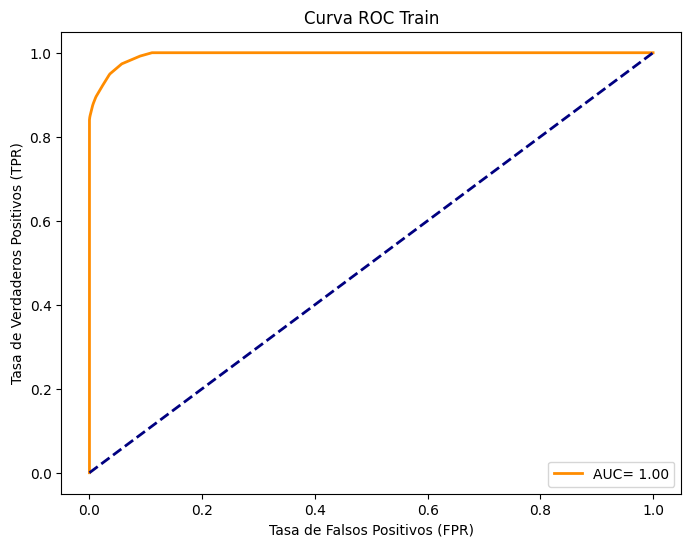


Áreabajo la curva ROC (AUC) Test: 1.00


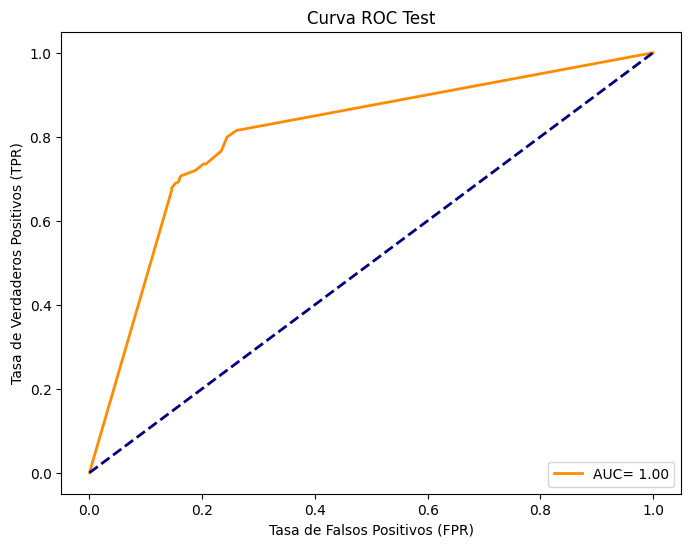

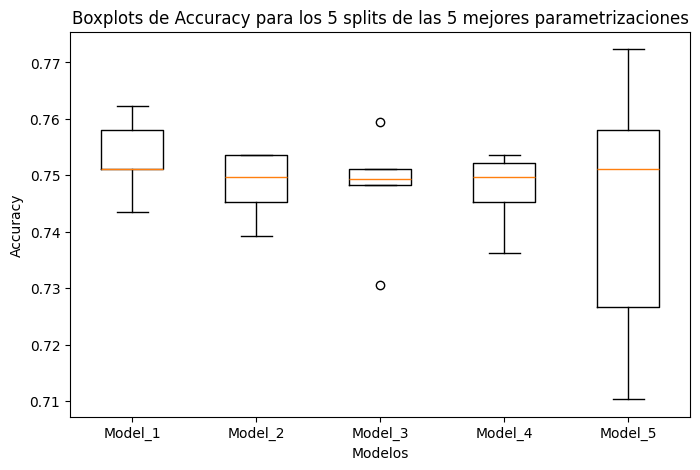

In [ ]:

params = {
    'max_depth': [20, 30, 40, 50],
    'min_samples_split': [2, 3, 5, 10, 20],
    'criterion': ["gini", "entropy"]
}
params= {
'max_depth': [2, 3, 5, 10, 20, 30],
'min_samples_split': [5, 10, 20, 50, 100],
'criterion': ["gini", "entropy"]
}

top7_3, best_model_3, indice3, df_importancia3 = modelo_gridsearch(X3, y, arbol1, params, refit='accuracy', scoring=scoring_metrics, top_n=7, )

## X4: Eliminación de variables menos importantes

In [222]:
df_importancia3.sort_values('Importancia', ascending=False).transpose()

,4,0,1,3,2,6,8,14,19,11,...,5,16,20,13,15,9,7,17,10,18
Variable,Mileage,Price,Levy,Engine volume,Prod. year,Airbags,Manufacturer_MERCEDES-BENZ,Fuel type_Petrol,Levy_nan_True,Category_Sedan,...,Cylinders,Drive wheels_Front,Turbo_True,Fuel type_Hybrid,Gear box type_Tiptronic,Manufacturer_TOYOTA,Manufacturer_LEXUS,Drive wheels_Rear,Category_Jeep,Wheel_Right-hand drive
Importancia,0.311848,0.219241,0.118191,0.101369,0.062764,0.033114,0.028584,0.020593,0.018089,0.014382,...,0.01278,0.010674,0.006004,0.005188,0.004919,0.004632,0.00455,0.004475,0.003817,0.000586


In [229]:
# Escojemos aquellas variables son una importancia superior al 1%

variables_importantes3= list(df_importancia3[df_importancia3['Importancia'] > 0.01].sort_values('Importancia', ascending=False)['Variable'])
variables_importantes3

['Mileage',
 'Price',
 'Levy',
 'Engine volume',
 'Prod. year',
 'Airbags',
 'Manufacturer_MERCEDES-BENZ',
 'Fuel type_Petrol',
 'Levy_nan_True',
 'Category_Sedan',
 'Leather interior_Yes',
 'Cylinders',
 'Drive wheels_Front']

In [ ]:
X4 = X3[variables_importantes3]

print(X3.shape)
print(X4.shape)

(4340, 21)
(4340, 13)


Mejor modelo encontrado:
 20 : DecisionTreeClassifier(max_depth=20, min_samples_split=5, random_state=2000)

Accuracy del mejor modelo:
 0.7508647606410548

Matriz de confusión de train:
 [[1771   77]
 [  78 1546]] 

Matriz de confusión de test:
 [[368 111]
 [ 99 290]] 


Informe de clasificación: train
               precision    recall  f1-score   support

       Black       0.96      0.96      0.96      1848
       White       0.95      0.95      0.95      1624

    accuracy                           0.96      3472
   macro avg       0.96      0.96      0.96      3472
weighted avg       0.96      0.96      0.96      3472


Informe de clasificación: test
               precision    recall  f1-score   support

       Black       0.79      0.77      0.78       479
       White       0.72      0.75      0.73       389

    accuracy                           0.76       868
   macro avg       0.76      0.76      0.76       868
weighted avg       0.76      0.76      0.76       868


Métric

,params,mean_test_accuracy,mean_test_precision_macro,mean_test_recall_macro,mean_test_f1_macro
20,"{'criterion': 'gini', 'max_depth': 20, 'min_sa...",0.750865,0.750480,0.749962,0.749706
45,"{'criterion': 'entropy', 'max_depth': 10, 'min...",0.746261,0.746006,0.746488,0.745632
25,"{'criterion': 'gini', 'max_depth': 30, 'min_sa...",0.745971,0.745547,0.744698,0.744616
50,"{'criterion': 'entropy', 'max_depth': 20, 'min...",0.745967,0.745146,0.745216,0.744993
55,"{'criterion': 'entropy', 'max_depth': 30, 'min...",0.744239,0.743430,0.742812,0.742905
46,"{'criterion': 'entropy', 'max_depth': 10, 'min...",0.743091,0.742855,0.743100,0.742358
21,"{'criterion': 'gini', 'max_depth': 20, 'min_sa...",0.739344,0.739180,0.738614,0.738187


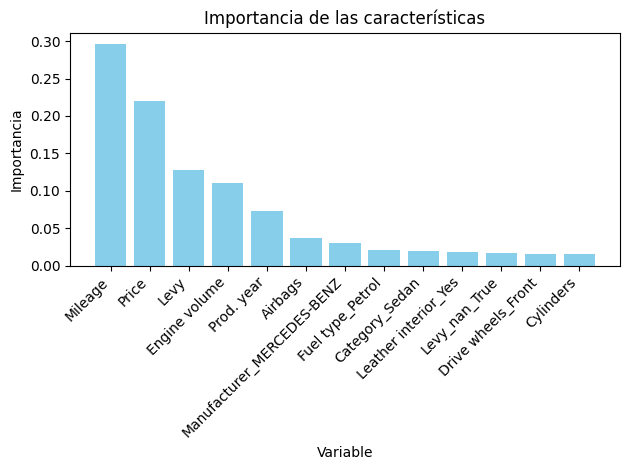


Áreabajo la curva ROC (AUC) Train: 0.99


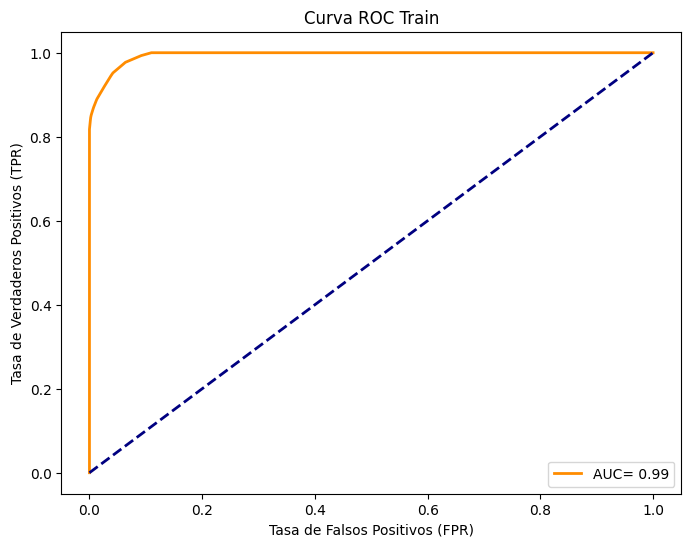


Áreabajo la curva ROC (AUC) Test: 0.99


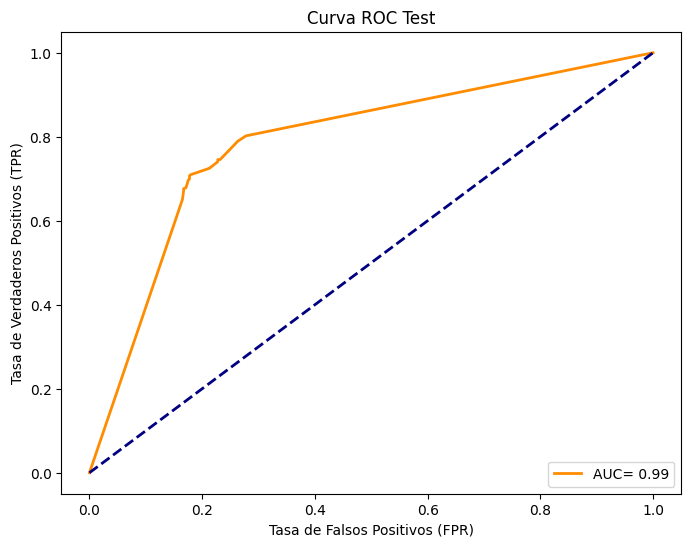

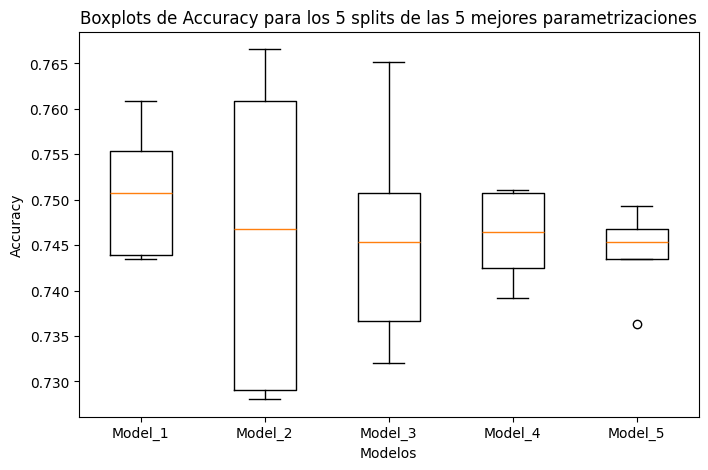

In [ ]:

params = {
    'max_depth': [20, 30, 40, 50],
    'min_samples_split': [2, 3, 5, 10, 20],
    'criterion': ["gini", "entropy"]
}

params= {
'max_depth': [2, 3, 5, 10, 20, 30],
'min_samples_split': [5, 10, 20, 50, 100],
'criterion': ["gini", "entropy"]
}


top7_4, best_model_4, indice4, df_importancia4 = modelo_gridsearch(X4, y, arbol1, params, refit='accuracy', scoring=scoring_metrics, top_n=7)

In [217]:
df_importancia4

,Variable,Importancia
0,Mileage,0.301802
1,Price,0.219794
2,Levy,0.111002
3,Engine volume,0.109914
4,Prod. year,0.078139
5,Airbags,0.039682
6,Manufacturer_MERCEDES-BENZ,0.028842
7,Fuel type_Petrol,0.020421
8,Levy_nan_True,0.016926
9,Category_Sedan,0.015915


### X5: Corrección correlación

Mejor modelo encontrado:
 20 : DecisionTreeClassifier(max_depth=20, min_samples_split=5, random_state=2000)

Accuracy del mejor modelo:
 0.7566317666328033

Matriz de confusión de train:
 [[1803   45]
 [  76 1548]] 

Matriz de confusión de test:
 [[366 113]
 [105 284]] 


Informe de clasificación: train
               precision    recall  f1-score   support

       Black       0.96      0.98      0.97      1848
       White       0.97      0.95      0.96      1624

    accuracy                           0.97      3472
   macro avg       0.97      0.96      0.96      3472
weighted avg       0.97      0.97      0.97      3472


Informe de clasificación: test
               precision    recall  f1-score   support

       Black       0.78      0.76      0.77       479
       White       0.72      0.73      0.72       389

    accuracy                           0.75       868
   macro avg       0.75      0.75      0.75       868
weighted avg       0.75      0.75      0.75       868


Métric

,params,mean_test_accuracy,mean_test_precision_macro,mean_test_recall_macro,mean_test_f1_macro
20,"{'criterion': 'gini', 'max_depth': 20, 'min_sa...",0.756632,0.756015,0.754926,0.755157
25,"{'criterion': 'gini', 'max_depth': 30, 'min_sa...",0.751159,0.750387,0.749413,0.749673
50,"{'criterion': 'entropy', 'max_depth': 20, 'min...",0.743664,0.743091,0.741823,0.742018
55,"{'criterion': 'entropy', 'max_depth': 30, 'min...",0.739055,0.738450,0.737538,0.737559
51,"{'criterion': 'entropy', 'max_depth': 20, 'min...",0.734449,0.734082,0.733217,0.732997
21,"{'criterion': 'gini', 'max_depth': 20, 'min_sa...",0.734157,0.733522,0.732129,0.732407
56,"{'criterion': 'entropy', 'max_depth': 30, 'min...",0.733296,0.733043,0.731946,0.731744


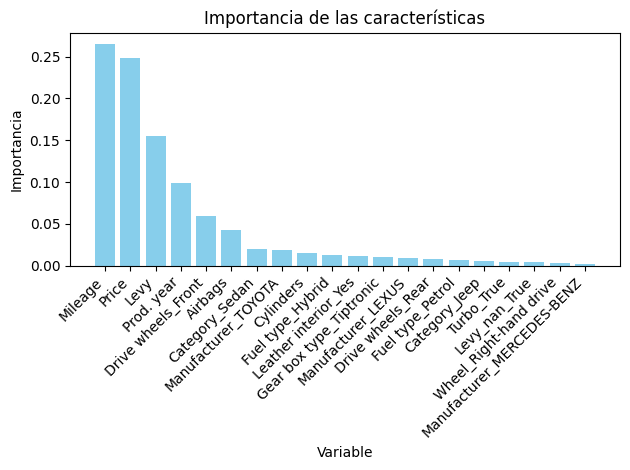


Áreabajo la curva ROC (AUC) Train: 1.00


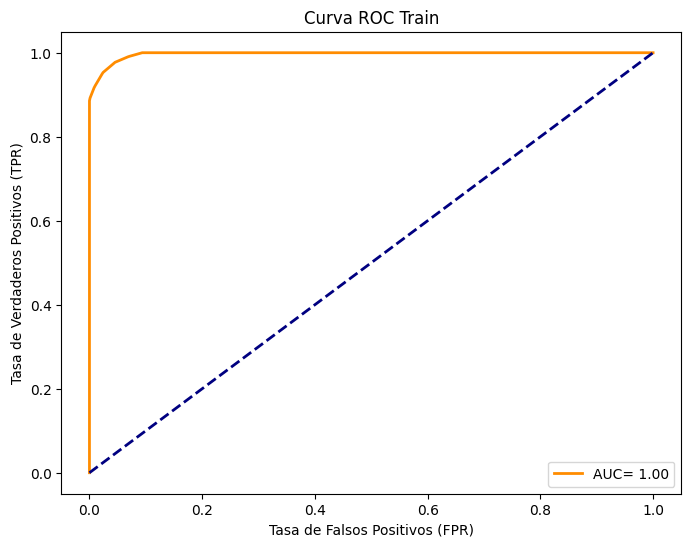


Áreabajo la curva ROC (AUC) Test: 1.00


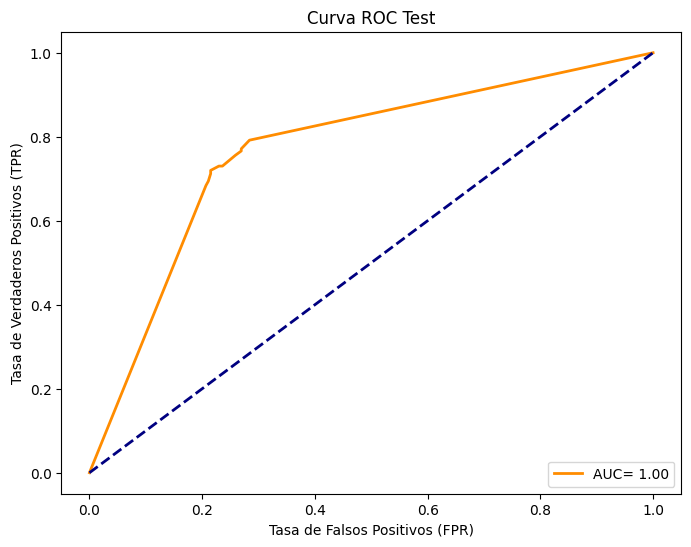

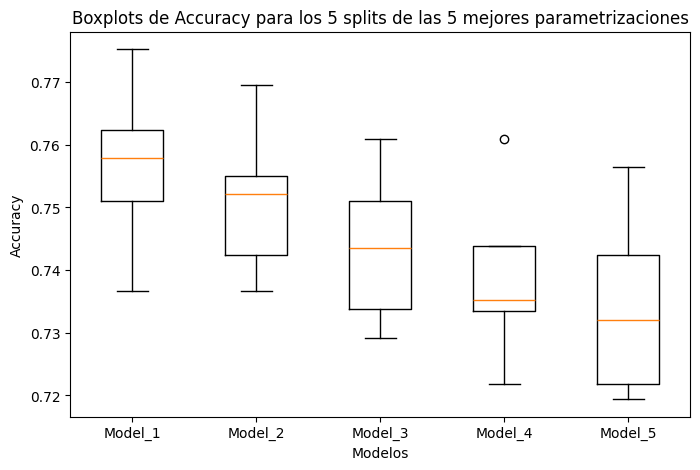

In [ ]:
# Nuevo set de variables independientes en el que borro 'Engine Volume' por ser la variable con más correlación con 'Levy' (de entre las variables restantes son las que mayor correlación presentan) 

X5= X3.drop(columns='Engine volume', axis=0)


params = {
    'max_depth': [20, 30, 40, 50],
    'min_samples_split': [2, 3, 5, 10, 20],
    'criterion': ["gini", "entropy"]
}
params= {
'max_depth': [2, 3, 5, 10, 20, 30],
'min_samples_split': [5, 10, 20, 50, 100],
'criterion': ["gini", "entropy"]
}

top7_5, best_model_5, indice5, df_importancia5 = modelo_gridsearch(X5, y, arbol1, params, refit='accuracy', scoring=scoring_metrics, top_n=7)

## RESUMEN DE RESULTADOS PARA ÁRBOLES DE CLASIFICACIÓN

In [236]:
print("Modelo 1:",top7['mean_test_accuracy'].iloc[0], best_model,  
      "\nModelo 2:",top7_2['mean_test_accuracy'].iloc[0], best_model_2,
      "\nModelo 3:",top7_3['mean_test_accuracy'].iloc[0], best_model_3, 
      "\nModelo 4:", top7_4['mean_test_accuracy'].iloc[0], best_model_4,
      "\nModelo 5:", top7_5['mean_test_accuracy'].iloc[0], best_model_5,
      ) 

Modelo 1: 0.7451089503037338 DecisionTreeClassifier(criterion='entropy', max_depth=20, min_samples_split=5,
                       random_state=2000) 
Modelo 2: 0.7523052681773889 DecisionTreeClassifier(max_depth=20, min_samples_split=5, random_state=2000) 
Modelo 3: 0.7531694068376423 DecisionTreeClassifier(max_depth=20, min_samples_split=5, random_state=2000) 
Modelo 4: 0.7508647606410548 DecisionTreeClassifier(max_depth=20, min_samples_split=5, random_state=2000) 
Modelo 5: 0.7566317666328033 DecisionTreeClassifier(max_depth=20, min_samples_split=5, random_state=2000)


Mejor modelo encontrado:
 112 : DecisionTreeClassifier(ccp_alpha=0.007, criterion='entropy', max_depth=10,
                       min_samples_leaf=15, min_samples_split=15,
                       random_state=2000)

Accuracy del mejor modelo:
 0.6589770489084237

Matriz de confusión de train:
 [[1343  505]
 [ 589 1035]] 

Matriz de confusión de test:
 [[337 142]
 [164 225]] 


Informe de clasificación: train
               precision    recall  f1-score   support

       Black       0.70      0.73      0.71      1848
       White       0.67      0.64      0.65      1624

    accuracy                           0.68      3472
   macro avg       0.68      0.68      0.68      3472
weighted avg       0.68      0.68      0.68      3472


Informe de clasificación: test
               precision    recall  f1-score   support

       Black       0.67      0.70      0.69       479
       White       0.61      0.58      0.60       389

    accuracy                           0.65       868
   macro 

,params,mean_test_accuracy,mean_test_precision_macro,mean_test_recall_macro,mean_test_f1_macro
113,"{'ccp_alpha': 0.007, 'criterion': 'entropy', '...",0.658977,0.658865,0.65472,0.654319
144,"{'ccp_alpha': 0.007, 'criterion': 'entropy', '...",0.658977,0.658865,0.65472,0.654319
112,"{'ccp_alpha': 0.007, 'criterion': 'entropy', '...",0.658977,0.658865,0.65472,0.654319
128,"{'ccp_alpha': 0.007, 'criterion': 'entropy', '...",0.658977,0.658865,0.65472,0.654319
129,"{'ccp_alpha': 0.007, 'criterion': 'entropy', '...",0.658977,0.658865,0.65472,0.654319
130,"{'ccp_alpha': 0.007, 'criterion': 'entropy', '...",0.658977,0.658865,0.65472,0.654319
131,"{'ccp_alpha': 0.007, 'criterion': 'entropy', '...",0.658977,0.658865,0.65472,0.654319


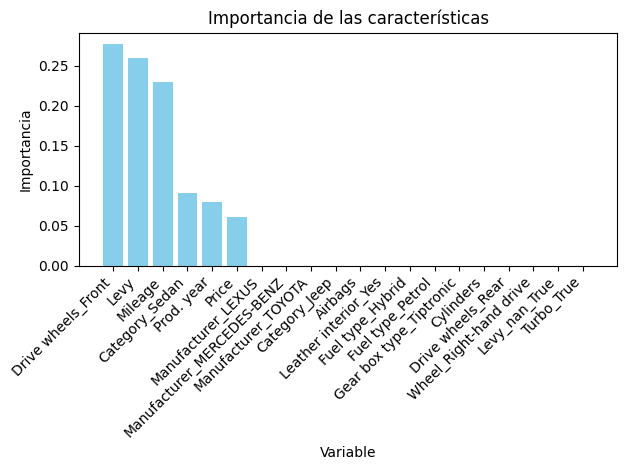


Áreabajo la curva ROC (AUC) Train: 0.74


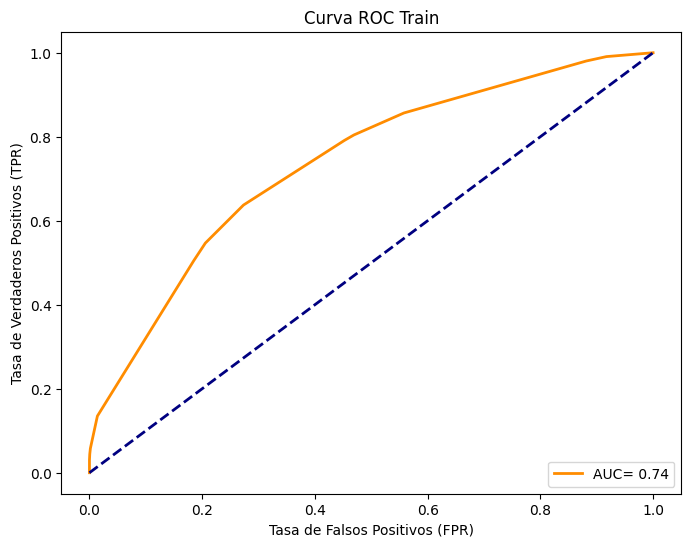


Áreabajo la curva ROC (AUC) Test: 0.74


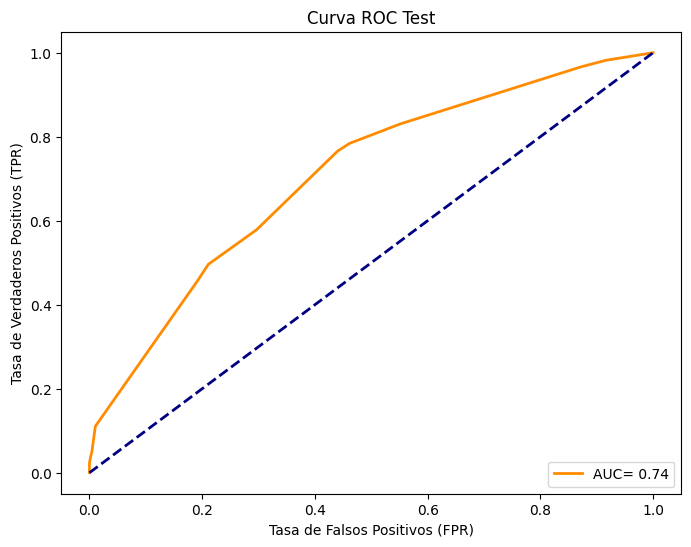

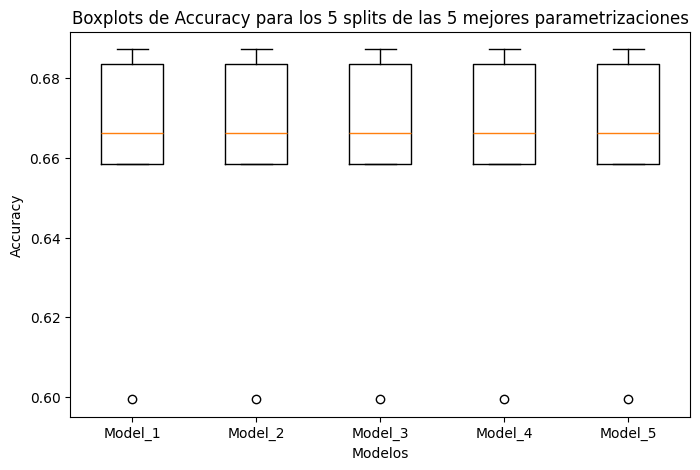

In [326]:
params= {
'max_depth': [2, 3, 5, 10, 20, 30],
'min_samples_split': [5, 10, 20, 50, 100],
'criterion': ["gini", "entropy"]
}

params = {
    'max_depth': [15, 17, 20, 22, 23, 24, 25],
    'min_samples_split': [2, 3, 4, 5, 10, 20],
    'criterion': ["gini", "entropy"]
}

params = {
    'max_depth': [ 5,7,10,15, 20],
    'min_samples_split': [15,17, 20, 25],
    'min_samples_leaf': [15,17, 20,23],
    'criterion': ["gini", "entropy"],
    'ccp_alpha': [0.007],
    'random_state': [seed]
}

# Busqueda de mejor modelo 
top7_arbol, best_model_arbol, indice_arbol, df_importancia_arbol = modelo_gridsearch(X5, y, arbol1, params, refit='accuracy', scoring=scoring_metrics, top_n=7)

In [268]:
df_importancia_arbol

,Variable,Importancia
15,Drive wheels_Front,0.277443
1,Levy,0.259908
3,Mileage,0.230363
10,Category_Sedan,0.091335
2,Prod. year,0.079604
0,Price,0.061348
6,Manufacturer_LEXUS,0.000000
7,Manufacturer_MERCEDES-BENZ,0.000000
8,Manufacturer_TOYOTA,0.000000
9,Category_Jeep,0.000000


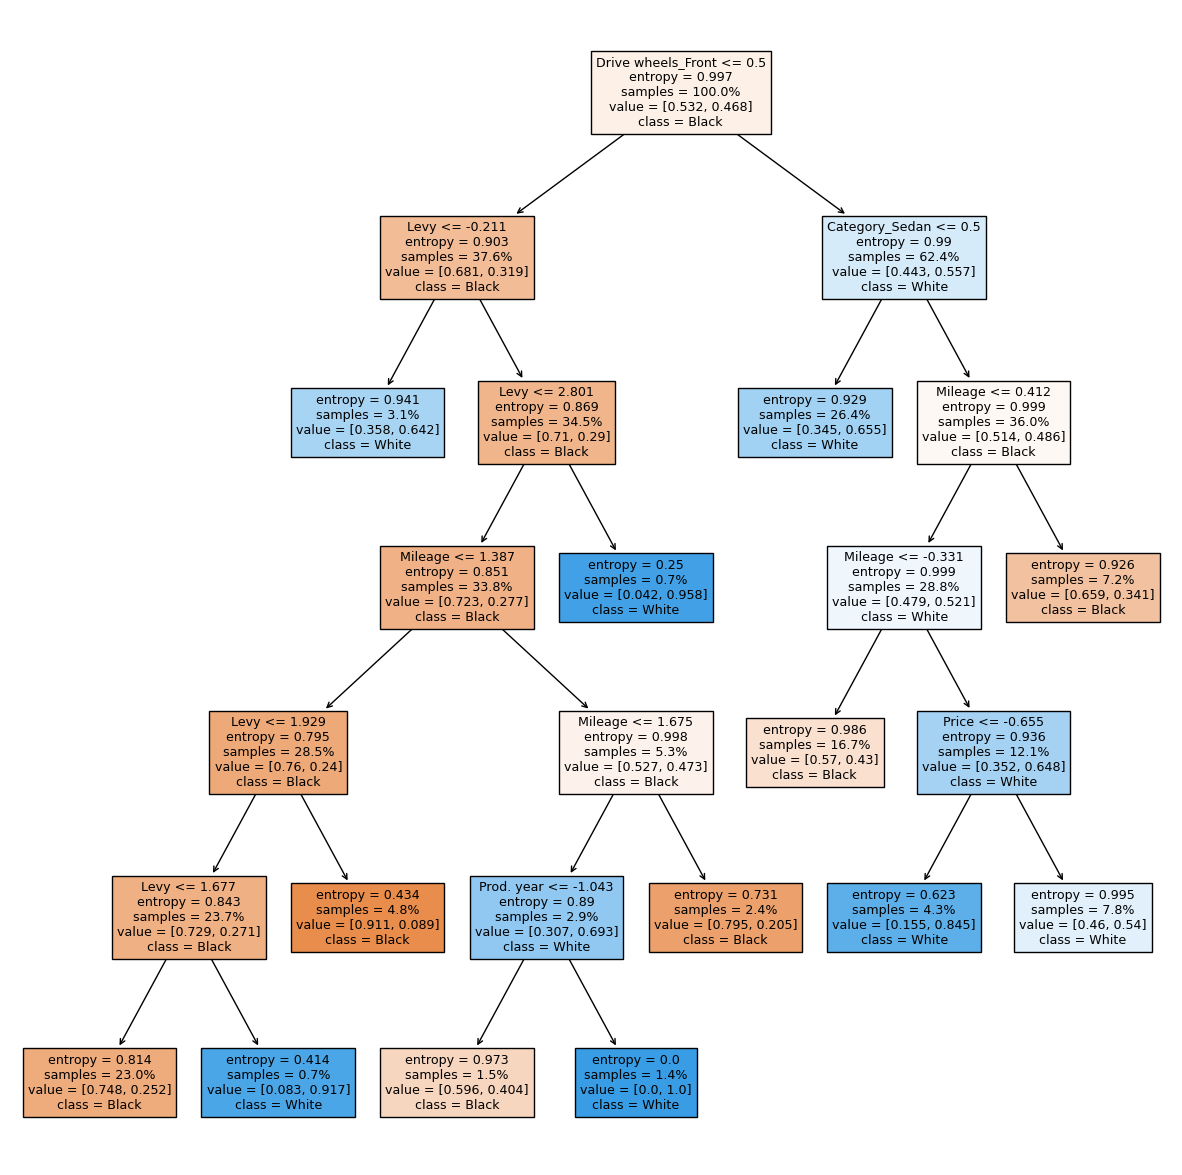

In [267]:
plt.figure(figsize=(15, 15))
plot_tree(best_model_arbol, feature_names=X5.columns.tolist(),
class_names=best_model_arbol.classes_, filled=True,
proportion= True)
plt.show()

In [269]:
# Reglas en formato de texto
print("Clases:", best_model_arbol.classes_)

print("Variables:", best_model_arbol.feature_names_in_)

tree_rules= export_text(best_model_arbol, feature_names=list(X5.columns),show_weights=True)
print(tree_rules)
print("Profundidad del árbol:", best_model_arbol.get_depth())

Clases: ['Black' 'White']
Variables: ['Price' 'Levy' 'Prod. year' 'Mileage' 'Cylinders' 'Airbags'
 'Manufacturer_LEXUS' 'Manufacturer_MERCEDES-BENZ' 'Manufacturer_TOYOTA'
 'Category_Jeep' 'Category_Sedan' 'Leather interior_Yes'
 'Fuel type_Hybrid' 'Fuel type_Petrol' 'Gear box type_Tiptronic'
 'Drive wheels_Front' 'Drive wheels_Rear' 'Wheel_Right-hand drive'
 'Levy_nan_True' 'Turbo_True']
|--- Drive wheels_Front <= 0.50
|   |--- Levy <= -0.21
|   |   |--- weights: [38.00, 68.00] class: White
|   |--- Levy >  -0.21
|   |   |--- Levy <= 2.80
|   |   |   |--- Mileage <= 1.39
|   |   |   |   |--- Levy <= 1.93
|   |   |   |   |   |--- Levy <= 1.68
|   |   |   |   |   |   |--- weights: [598.00, 201.00] class: Black
|   |   |   |   |   |--- Levy >  1.68
|   |   |   |   |   |   |--- weights: [2.00, 22.00] class: White
|   |   |   |   |--- Levy >  1.93
|   |   |   |   |   |--- weights: [153.00, 15.00] class: Black
|   |   |   |--- Mileage >  1.39
|   |   |   |   |--- Mileage <= 1.67
|   |   |   

# RandomForest

In [ ]:
rf = RandomForestClassifier(n_estimators = 60,bootstrap = True, max_depth = 20, min_samples_split=10, criterion='entropy',min_samples_leaf= 10,random_state=123)

paramsrf = {
'n_estimators' : [50,100,150,200,250],
'max_depth': [2, 3, 5, 10, 20],
'bootstrap': [True, False],
'min_samples_leaf' : [3,10,30],
'min_samples_split': [5, 10, 20, 50, 100],
'criterion': ["gini", "entropy"]
}

paramsrf = {
'n_estimators' : [300],
'max_depth': [2, 3, 5, 10, 12],
'bootstrap': [True, False],
'min_samples_leaf' : [10,15,20,30],
'min_samples_split': [ 15,20,30],
'criterion': ['gini', 'entropy'],
'max_features': ['sqrt','log2'],
'class_weight': [None, 'balanced']
}

Mejor modelo encontrado:
 3482 : RandomForestClassifier(bootstrap=False, criterion='entropy', max_depth=12,
                       min_samples_leaf=10, min_samples_split=15,
                       n_estimators=300, random_state=123)

Accuracy del mejor modelo:
 0.7511529450790952

Matriz de confusión de train:
 [[1530  318]
 [ 288 1336]] 

Matriz de confusión de test:
 [[367 112]
 [ 96 293]] 


Informe de clasificación: train
               precision    recall  f1-score   support

       Black       0.84      0.83      0.83      1848
       White       0.81      0.82      0.82      1624

    accuracy                           0.83      3472
   macro avg       0.82      0.83      0.82      3472
weighted avg       0.83      0.83      0.83      3472


Informe de clasificación: test
               precision    recall  f1-score   support

       Black       0.79      0.77      0.78       479
       White       0.72      0.75      0.74       389

    accuracy                           0.76  

,params,mean_test_accuracy,mean_test_precision_macro,mean_test_recall_macro,mean_test_f1_macro
3487,"{'bootstrap': False, 'class_weight': None, 'cr...",0.751153,0.750823,0.750214,0.749970
3482,"{'bootstrap': False, 'class_weight': None, 'cr...",0.751153,0.750823,0.750214,0.749970
3542,"{'bootstrap': False, 'class_weight': None, 'cr...",0.751153,0.750823,0.750214,0.749970
3547,"{'bootstrap': False, 'class_weight': None, 'cr...",0.751153,0.750823,0.750214,0.749970
2882,"{'bootstrap': False, 'class_weight': None, 'cr...",0.750866,0.750671,0.749831,0.749608
2887,"{'bootstrap': False, 'class_weight': None, 'cr...",0.750866,0.750671,0.749831,0.749608
2942,"{'bootstrap': False, 'class_weight': None, 'cr...",0.750866,0.750671,0.749831,0.749608


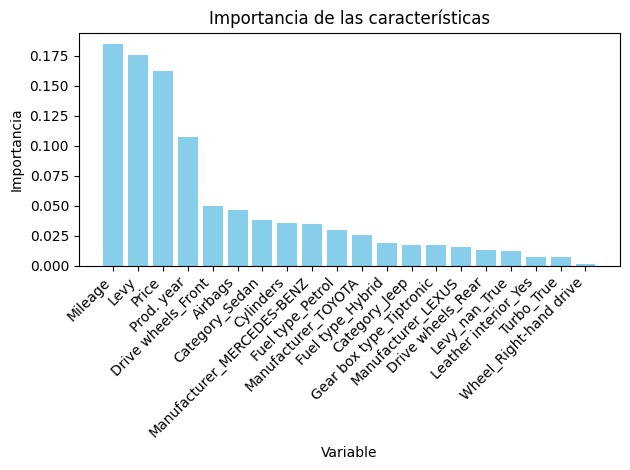


Áreabajo la curva ROC (AUC) Train: 0.92


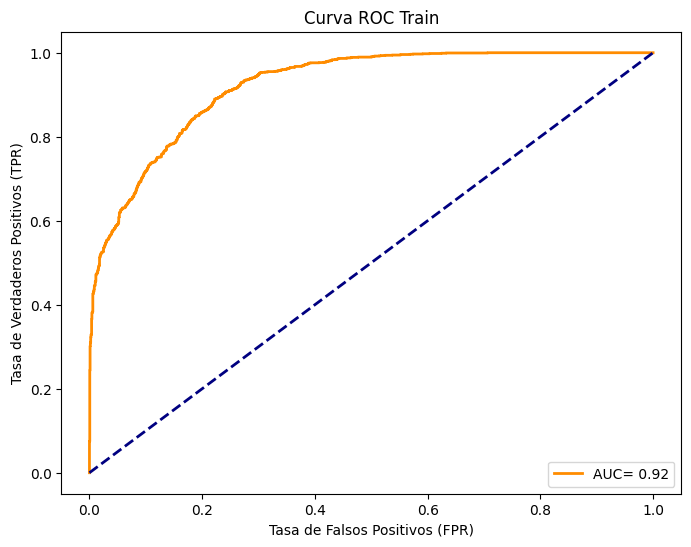


Áreabajo la curva ROC (AUC) Test: 0.92


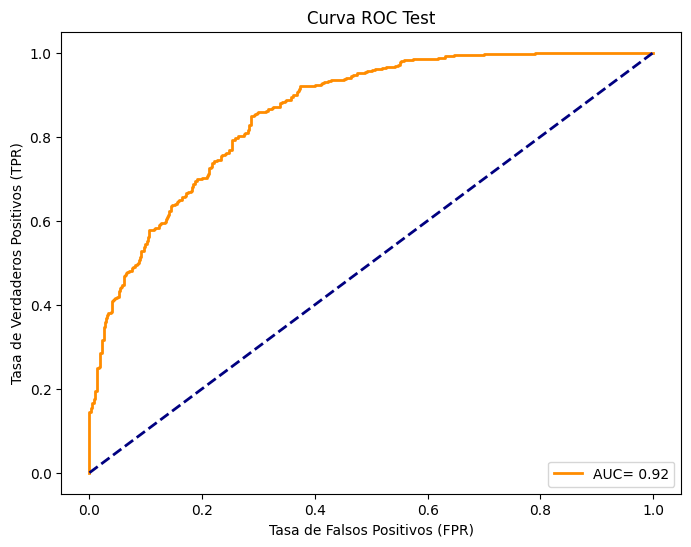

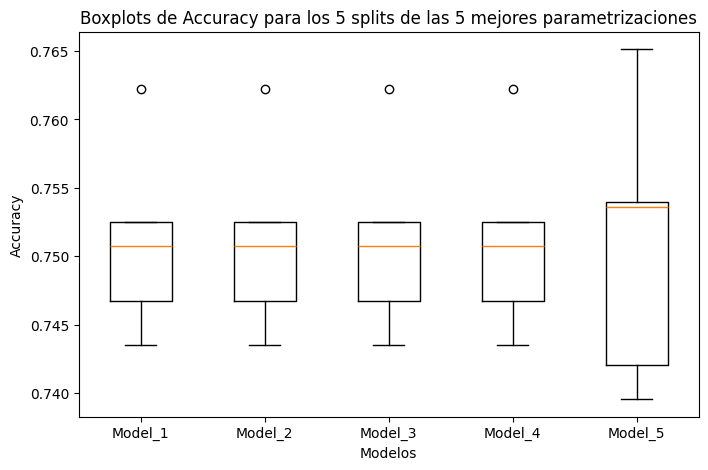

In [325]:
#top7_rf, best_model_rf, indicerf, cr_rf = modelo_gridsearch(X2, y2, rf, params= paramsrf, scoring=scoring_metrics) 
top7_rf, best_model_rf, indice_rf, df_importancia_rf = modelo_gridsearch(X5, y, rf, params= paramsrf, scoring=scoring_metrics, refit='accuracy') 
#print("Mejor modelo encontrado:\n", best_model_rf)
#print("Accuracy del mejor modelo:\n", top7_rf['mean_test_accuracy'].iloc[0])
#print(cr_rf)
#top7_rf

# XGBoost

In [ ]:
xgb_classifier = XGBClassifier()

y2 = y.map(lambda x: 0 if x == 'Black' else 1)

X_train, X_test, y_train, y_test = train_test_split(X5, y2, test_size=0.2, random_state=123)

xgb_classifier.fit(X_train, y_train)
y_pred_base = xgb_classifier.predict(X_test)

accuracy_a = accuracy_score(y_test, y_pred_base)
print(f'Precisión de gradient boosting: {accuracy_a}')

Precisión de gradient boosting: 0.7580645161290323


Mejor modelo encontrado:
 0 : XGBClassifier(base_score=None, booster='gbtree', callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eta=0.1, eval_metric=None,
              feature_types=None, feature_weights=None, gamma=1,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=15, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=None, ...)

Accuracy del mejor modelo:
 0.7557647253954761

Matriz de confusión de train:
 [[1748  100]
 [  85 1539]] 

Matriz de confusión de test:
 [[371 108]
 [ 97 292]] 


Informe de clasificación: train
               precision    r

,params,mean_test_accuracy,mean_test_precision_macro,mean_test_recall_macro,mean_test_f1_macro
0,{},0.755765,0.755411,0.754687,0.754517


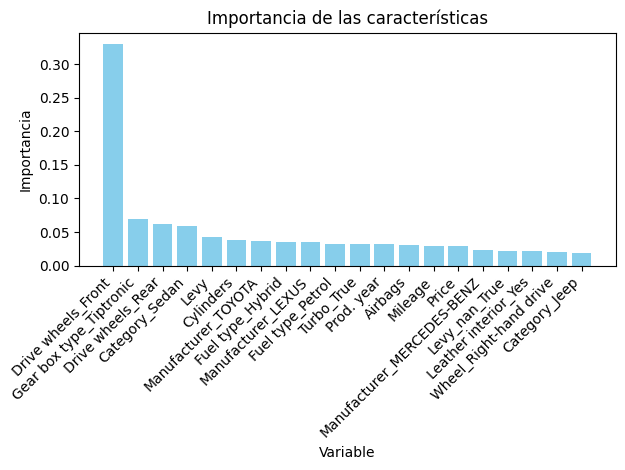


Áreabajo la curva ROC (AUC) Train: 0.99


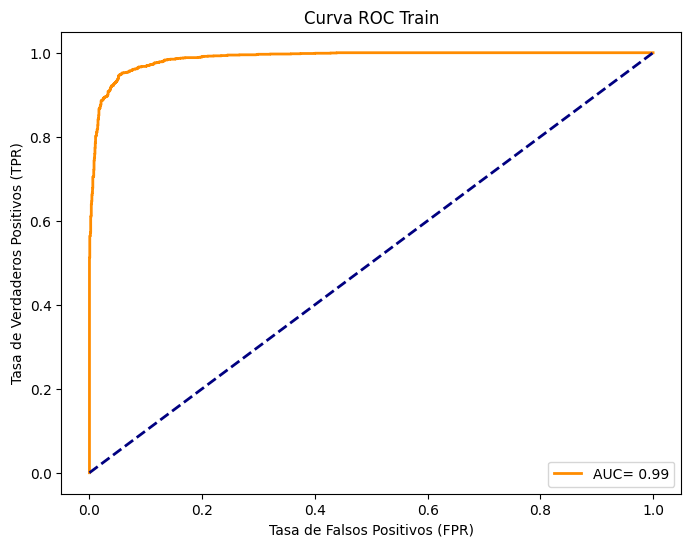


Áreabajo la curva ROC (AUC) Test: 0.99


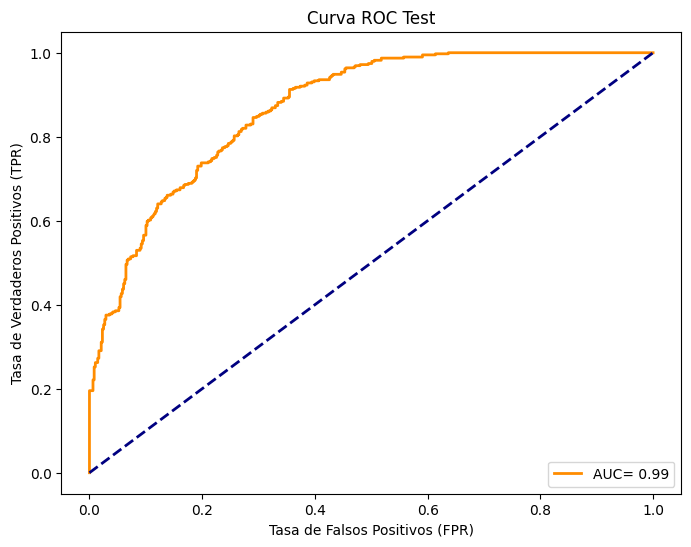

ValueError: Dimensions of labels and X must be compatible

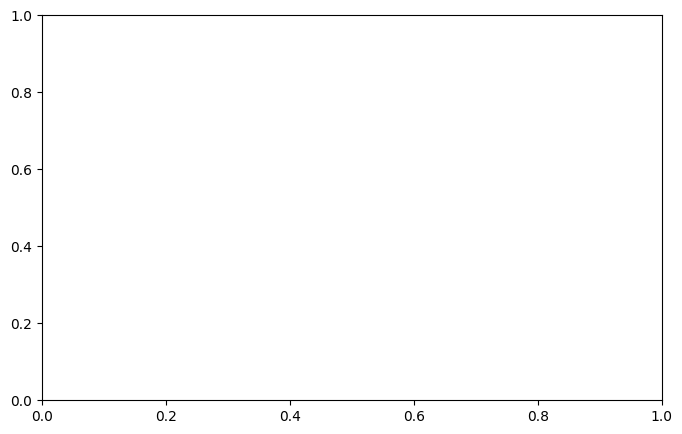

In [332]:
params_xgb1 = {
}
top7_xgb1, best_model_xgb1, indice_xgb1, df_importancia_xgb1 = modelo_gridsearch(X5, y2, xgb_classifier, params= params_xgb1, scoring=scoring_metrics, refit='accuracy') 

In [ ]:
params_xgb1 = {
    'n_estimators': [100, 200, 300, 400],      
    'max_depth': [3, 5, 7, 10],                
    'min_child_weight': [1, 3, 5],             
    'gamma': [0, 0.1, 0.3, 0.5],               
    'subsample': [0.6, 0.8, 1.0],              
    'colsample_bytree': [0.6, 0.8, 1.0],       
    'reg_alpha': [0, 0.01, 0.1, 1],            
    'reg_lambda': [1, 1.5, 2],                 
    'learning_rate': [0.01, 0.05, 0.1, 0.2], 
    'scale_pos_weight': [1]                     
}

Mejor modelo encontrado:
 6067 : XGBClassifier(base_score=None, booster='gbtree', callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.6, device=None, early_stopping_rounds=None,
              enable_categorical=False, eta=0.1, eval_metric=None,
              feature_types=None, feature_weights=None, gamma=0,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.2, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=7, max_leaves=None,
              min_child_weight=1, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=None, ...)

Accuracy del mejor modelo:
 0.7773582402089856

Matriz de confusión de train:
 [[1781   67]
 [  51 1573]] 

Matriz de confusión de test:
 [[378 101]
 [ 95 294]] 


Informe de clasificación: train
               precision    reca

,params,mean_test_accuracy,mean_test_precision_macro,mean_test_recall_macro,mean_test_f1_macro
6067,"{'colsample_bytree': 0.6, 'gamma': 0, 'learnin...",0.777358,0.777194,0.776806,0.776443
13393,"{'colsample_bytree': 0.6, 'gamma': 0.1, 'learn...",0.776787,0.776668,0.776155,0.775814
3133,"{'colsample_bytree': 0.6, 'gamma': 0, 'learnin...",0.776497,0.776238,0.775768,0.775508
6496,"{'colsample_bytree': 0.6, 'gamma': 0, 'learnin...",0.775920,0.775830,0.774781,0.774687
6505,"{'colsample_bytree': 0.6, 'gamma': 0, 'learnin...",0.775635,0.775113,0.774993,0.774727
13402,"{'colsample_bytree': 0.6, 'gamma': 0.1, 'learn...",0.775635,0.775330,0.774736,0.774553
54865,"{'colsample_bytree': 0.8, 'gamma': 0.5, 'learn...",0.775056,0.774944,0.774455,0.774080


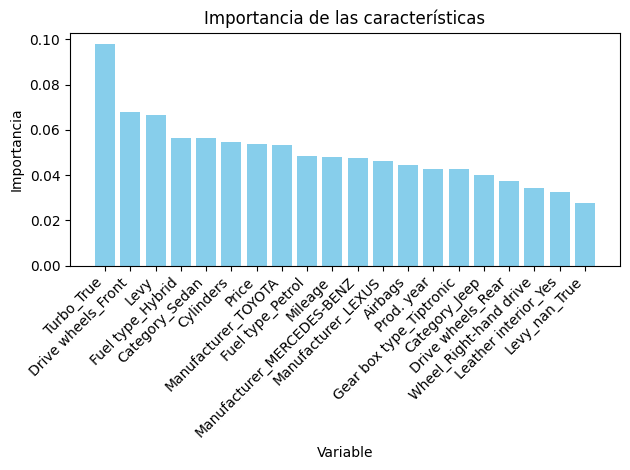


Áreabajo la curva ROC (AUC) Train: 1.00


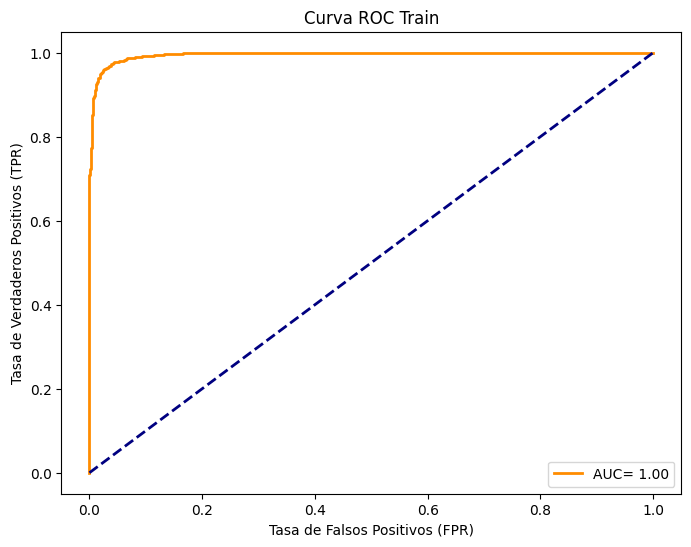


Áreabajo la curva ROC (AUC) Test: 1.00


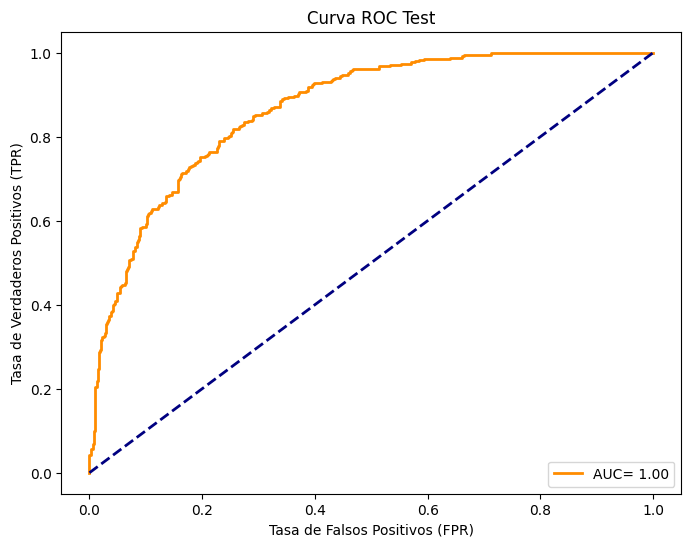

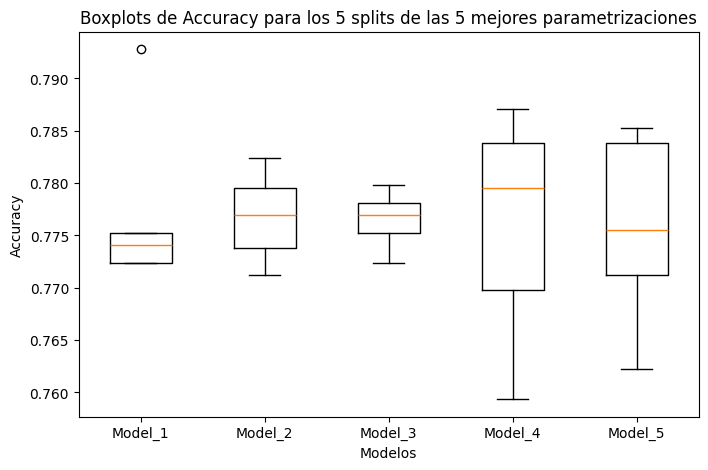

In [ ]:
top7_xgb, best_model_xgb, indice_xgb, df_importancia_xgb = modelo_gridsearch(X5, y2, xgb_classifier, params= params_xgb1, scoring=scoring_metrics, refit='accuracy') 

Mejor modelo encontrado:
 417 : XGBClassifier(base_score=None, booster='gbtree', callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eta=0.1, eval_metric=None,
              feature_types=None, feature_weights=None, gamma=0,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=10, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=None, ...)

Accuracy del mejor modelo:
 0.7736130864760641

Matriz de confusión de train:
 [[1823   25]
 [   8 1616]] 

Matriz de confusión de test:
 [[386  93]
 [ 95 294]] 


Informe de clasificación: train
               precision    

,params,mean_test_accuracy,mean_test_precision_macro,mean_test_recall_macro,mean_test_f1_macro
417,"{'gamma': 0, 'learning_rate': 0.1, 'max_depth'...",0.773613,0.773693,0.772507,0.772381
423,"{'gamma': 0, 'learning_rate': 0.1, 'max_depth'...",0.772464,0.772343,0.771614,0.771360
414,"{'gamma': 0, 'learning_rate': 0.1, 'max_depth'...",0.771602,0.771199,0.770610,0.770493
413,"{'gamma': 0, 'learning_rate': 0.1, 'max_depth'...",0.771024,0.770949,0.770036,0.769838
702,"{'gamma': 0.1, 'learning_rate': 0.05, 'max_dep...",0.770739,0.770444,0.769916,0.769678
361,"{'gamma': 0, 'learning_rate': 0.1, 'max_depth'...",0.770737,0.770422,0.769838,0.769673
711,"{'gamma': 0.1, 'learning_rate': 0.05, 'max_dep...",0.770734,0.770748,0.770029,0.769667


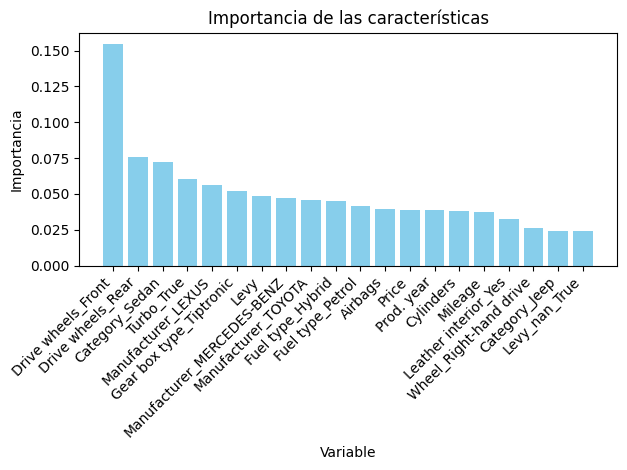


Áreabajo la curva ROC (AUC) Train: 1.00


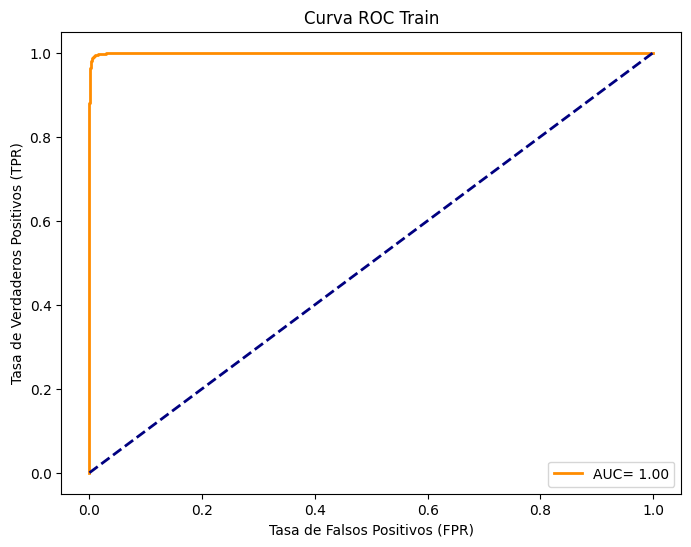


Áreabajo la curva ROC (AUC) Test: 1.00


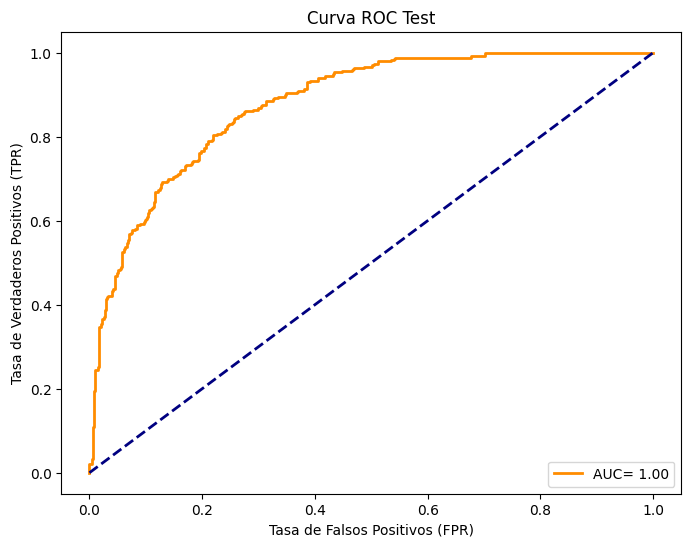

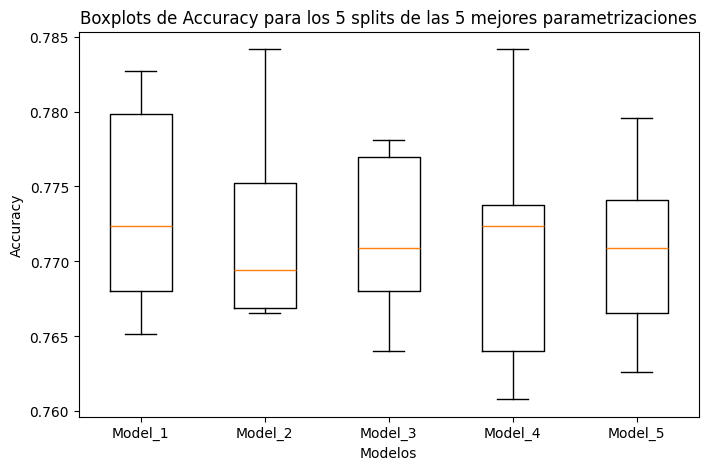

In [334]:
params_xgb2 = {
    'n_estimators': [100, 200],
    'gamma': [0, 0.1, 0.3, 0.5],
    'reg_alpha': [0, 0.01, 0.1, 1],
    'reg_lambda': [1, 1.5, 2],
    'max_depth': [5, 7, 10],
    'learning_rate': [0.01, 0.05, 0.1],
    'subsample': [0.8, 1.0]
}

top7_xgb2, best_model_xgb2, indice_xgb2, df_importancia_xgb2 = modelo_gridsearch(X5, y2, xgb_classifier, params= params_xgb2, scoring=scoring_metrics, refit='accuracy') 

Mejor modelo encontrado:
 123 : XGBClassifier(base_score=None, booster='gbtree', callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=False, eta=0.1, eval_metric=None,
              feature_types=None, feature_weights=None, gamma=0.1,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=4, max_leaves=None,
              min_child_weight=5, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=None, ...)

Accuracy del mejor modelo:
 0.753171065453113

Matriz de confusión de train:
 [[1547  301]
 [ 292 1332]] 

Matriz de confusión de test:
 [[370 109]
 [111 278]] 


Informe de clasificación: train
               precision    reca

,params,mean_test_accuracy,mean_test_precision_macro,mean_test_recall_macro,mean_test_f1_macro
123,"{'colsample_bytree': 0.8, 'gamma': 0.1, 'learn...",0.753171,0.752992,0.752473,0.752086
428,"{'colsample_bytree': 0.8, 'gamma': 1, 'learnin...",0.751441,0.751263,0.750965,0.750472
125,"{'colsample_bytree': 0.8, 'gamma': 0.1, 'learn...",0.751158,0.750689,0.750658,0.750237
268,"{'colsample_bytree': 0.8, 'gamma': 0.5, 'learn...",0.750867,0.750570,0.750345,0.749886
120,"{'colsample_bytree': 0.8, 'gamma': 0.1, 'learn...",0.750865,0.750418,0.750231,0.749870
221,"{'colsample_bytree': 0.8, 'gamma': 0.5, 'learn...",0.750577,0.750136,0.749854,0.749530
267,"{'colsample_bytree': 0.8, 'gamma': 0.5, 'learn...",0.750576,0.750328,0.749368,0.749239


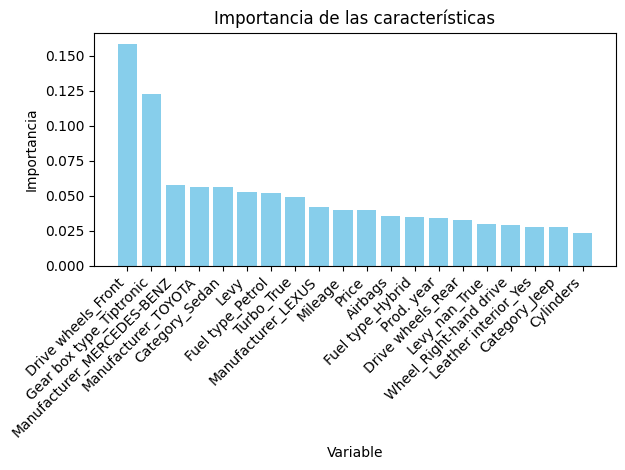


Áreabajo la curva ROC (AUC) Train: 0.92


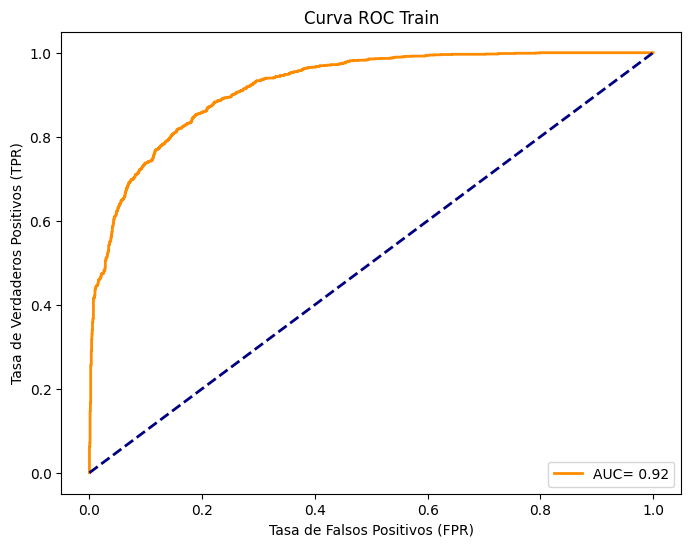


Áreabajo la curva ROC (AUC) Test: 0.92


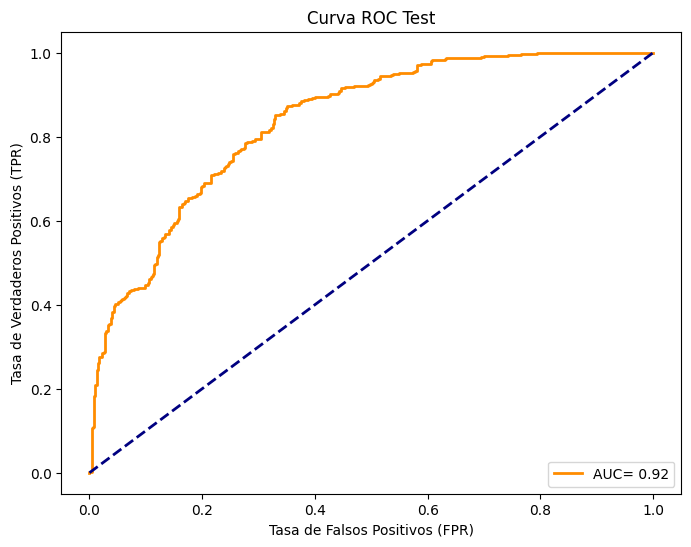

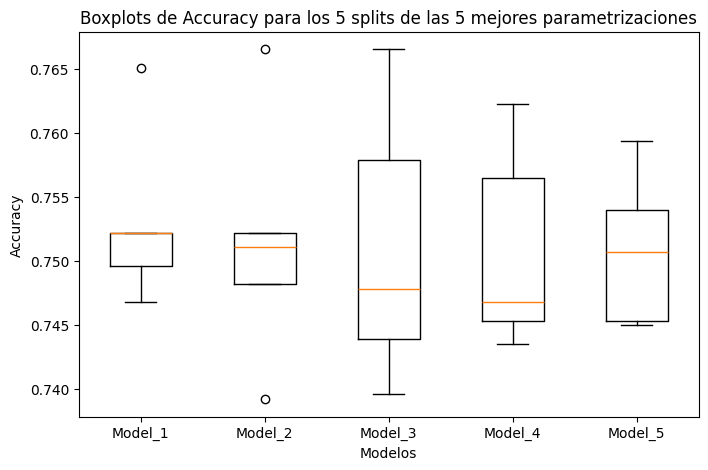

In [ ]:
params_xgb3 = {
    'n_estimators': [100, 200, 300],
    'eta': [0.01, 0.05, 0.1],
    'max_depth': [3, 4, 5],
    'min_child_weight': [3, 5, 7],
    'gamma': [0, 0.5, 1],
    'subsample': [0.6, 0.7, 0.8],
    'colsample_bytree': [0.6, 0.7, 0.8],
    'reg_alpha': [0, 0.5, 1, 5],
    'reg_lambda': [1, 2, 5]
}
params_xgb3 = {
    'n_estimators': [200, 300],         
    'learning_rate': [0.03, 0.05, 0.1],        
    'max_depth': [3, 4],                
    'min_child_weight': [ 5, 6, 7],          
    'subsample': [0.8],             
    'colsample_bytree': [0.8],      
    'reg_alpha': [0, 1],                 
    'reg_lambda': [1, 2],
    'gamma': [0.1, 0.5, 1]
}
top7_xgb3, best_model_xgb3, indice_xgb3, df_importancia_xgb3 = modelo_gridsearch(X5, y2, xgb_classifier, params= params_xgb3, scoring=scoring_metrics, refit='accuracy') 